# Семинар 7. Метрические методы. Задача кластеризации.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

### Метрики и расстояния

Рассмотрим набор

$$S=\{x_1,\ldots,x_n\}\subset\mathbb R^d,\qquad |S|=n.$$

Функция $\rho:\mathbb X\times\mathbb X\to[0,\infty)$ называется _метрикой_, если для любых $x,z,u\in\mathbb X$ выполнены условия:

* $\rho(x,z)=0\iff x=z, \quad \text{(Тождественность)}$;
* $\rho(x,z)\geqslant 0, \quad \text{(Положительность)}$;
* $\rho(x,z)=\rho(z,x), \quad \text{(Симметричность)}$;
* $\rho(x,u)\leq\rho(x,z)+\rho(z,u), \quad \text{(Неравенство треугольника)}$.

**Примеры метрик**

- Евклидова: $\rho(x,z)=\|x-z\|_2=\sqrt{\sum_{j=1}^{d}(x_j-z_j)^2}$.
- Манхэттенская: $\rho(x,z)=\|x-z\|_1=\sum_{j=1}^{d}|x_j-z_j|$.
- Чебышёва: $\rho(x,z)=\|x-z\|_\infty=\max_{1\leq j\leq d}|x_j-z_j|$.
- Минковского: $\rho(x,z)=\|x-z\|_p=\left(\sum_{j=1}^{d}|x_j-z_j|^p\right)^{1/p}$, $1\leq p<\infty$.

В метрических методах используются не только формальные метрики, но и *расстояния*. Например, косинусное расстояние для ненулевых векторов:

$$d_{\cos}(x,z) = 1-\cos(x, z) = 1-\frac{x^\top z}{\|x\|_2\|z\|_2}.$$

<details>
<summary><b>Является ли косинусное расстояние метрикой?</b></summary>

1. Нет. Возьмём единичные векторы в $\mathbb R^2$:

$$a=(1,0),\qquad b=\left(\frac1{\sqrt2},\frac1{\sqrt2}\right),\qquad c=(0,1).$$

$$d_{\cos}(a,c)=1,\qquad d_{\cos}(a,b)=d_{\cos}(b,c)=1-\frac1{\sqrt2}.$$

$$d_{\cos}(a,c)=1>2-\sqrt2=d_{\cos}(a,b)+d_{\cos}(b,c).$$

2. На всех ненулевых векторах также нарушается тождественность: $d_{\cos}((1,0),(2,0))=0$.

</details>

<details>
<summary><b>Другие расстояния</b></summary>

- [Расстояние Канберры](https://en.wikipedia.org/wiki/Canberra_distance)
- [расстояние Хэмминга](https://ru.wikipedia.org/wiki/%D0%A0%D0%B0%D1%81%D1%81%D1%82%D0%BE%D1%8F%D0%BD%D0%B8%D0%B5_%D0%A5%D1%8D%D0%BC%D0%BC%D0%B8%D0%BD%D0%B3%D0%B0)
- [расстояние Джаккарда](https://ru.wikipedia.org/wiki/%D0%9A%D0%BE%D1%8D%D1%84%D1%84%D0%B8%D1%86%D0%B8%D0%B5%D0%BD%D1%82_%D0%96%D0%B0%D0%BA%D0%BA%D0%B0%D1%80%D0%B0)
- [DTW](https://ru.wikipedia.org/wiki/%D0%90%D0%BB%D0%B3%D0%BE%D1%80%D0%B8%D1%82%D0%BC_%D0%B4%D0%B8%D0%BD%D0%B0%D0%BC%D0%B8%D1%87%D0%B5%D1%81%D0%BA%D0%BE%D0%B9_%D1%82%D1%80%D0%B0%D0%BD%D1%81%D1%84%D0%BE%D1%80%D0%BC%D0%B0%D1%86%D0%B8%D0%B8_%D0%B2%D1%80%D0%B5%D0%BC%D0%B5%D0%BD%D0%BD%D0%BE%D0%B9_%D1%88%D0%BA%D0%B0%D0%BB%D1%8B)
- [Расстояние Левенштейна](https://ru.wikipedia.org/wiki/%D0%A0%D0%B0%D1%81%D1%81%D1%82%D0%BE%D1%8F%D0%BD%D0%B8%D0%B5_%D0%9B%D0%B5%D0%B2%D0%B5%D0%BD%D1%88%D1%82%D0%B5%D0%B9%D0%BD%D0%B0)

</details>

### Масштаб признаков

Сравним людей по возрасту и росту, используя евклидово расстояние:

| Объект | Возраст, годы | Рост, метры |
|---|---:|---:|
| $x$ | 40 | 1,70 |
| $A$ | 41 | 1,90 |
| $B$ | 45 | 1,71 |

Если рост записан в метрах:

$$\rho(x,A)=\sqrt{1^2+0{,}20^2}\approx1{,}02,\qquad
\rho(x,B)=\sqrt{5^2+0{,}01^2}\approx5{,}00.$$

Ближайший объект — $A$. Запишем рост тех же людей в сантиметрах:

$$\rho(x,A)=\sqrt{1^2+20^2}\approx20{,}02,\qquad
\rho(x,B)=\sqrt{5^2+1^2}\approx5{,}10.$$

Теперь ближайший объект — $B$: изменились только единицы измерения роста, но его вклад в квадрат расстояния увеличился в $10^4$ раз.

Стандартизация по обучающей выборке:

$$\widetilde x_{ij}=\frac{x_{ij}-\bar x_j}{s_j},\qquad s_j>0.$$

Она устраняет зависимость от единиц измерения, но равный вес стандартизованных признаков подходит не для каждой задачи.

### Проклятие размерности

Предсказание по ближайшим объектам опирается на наличие похожих обучающих примеров. При росте числа существенных признаков сохранить такую локальную плотность может потребовать значительно больше данных.

**Покрытие пространства.** Разобьём каждый из $d$ признаков на $m$ интервалов. Получится $m^d$ ячеек. При равномерном распределении на $[0,1]^d$ в ячейке ожидается $n/m^d$ обучающих объектов.

$$m=100:\qquad d=1\Rightarrow100\text{ ячеек},\qquad d=10\Rightarrow10^{20}\text{ ячеек}.$$

## Метод ближайших соседей (KNN)

Обучающая выборка для задачи классификации:

$$\mathcal D=\{(x_i,y_i)\}_{i=1}^{n},\qquad x_i\in\mathbb R^d,\qquad
 y_i\in\mathcal Y=\{1,\ldots,L\}.$$

Для объекта $x$ упорядочим индексы обучающих объектов по расстоянию:

$$\rho(x,x_{\pi_1(x)})\leq\cdots\leq\rho(x,x_{\pi_n(x)}),\qquad
I_r(x)=\{\pi_1(x),\ldots,\pi_r(x)\},\qquad1\leq r\leq n.$$

Равенства разрешаем по фиксированному правилу. Предсказание класса:

$$a(x)=\arg\max_{c\in\mathcal Y}\sum_{i\in I_r(x)}\mathbb I[y_i=c].$$

### Взвешенное голосование

$$a(x)=\arg\max_{c\in\mathcal Y}\sum_{t=1}^{r}
 w_t(x)\,\mathbb I[y_{\pi_t(x)}=c],\qquad w_t(x)\geq0,\quad\sum_{t=1}^r w_t(x)>0.$$

- Равные веса: $w_t(x)=1$.
- Веса по рангу: $w_t(x)=q^{t-1}$, $0<q<1$.
- Веса по расстоянию: более близким объектам назначаются большие веса; совпадения с обучающими объектами обрабатываются отдельно.

Гиперпараметры: $r$, расстояние, весовая схема. Подбираются по валидационной выборке.

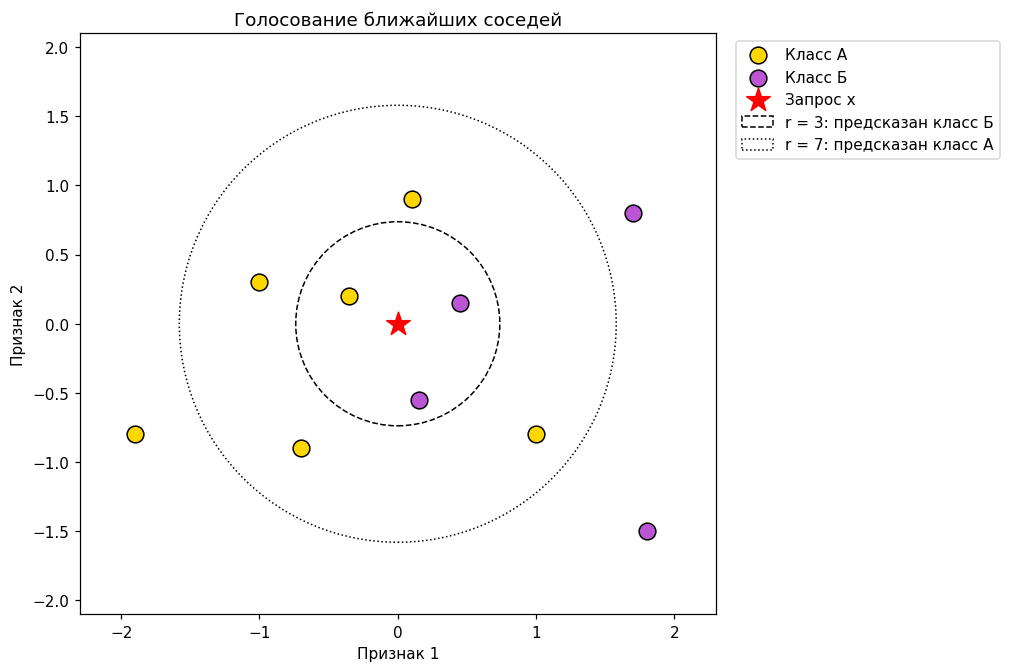

In [ ]:
from matplotlib.patches import Circle

X_vote = np.array([
    [-0.35, 0.20], [0.45, 0.15], [0.15, -0.55], [0.10, 0.90],
    [-1.00, 0.30], [-0.70, -0.90], [1.00, -0.80], [1.70, 0.80],
    [-1.90, -0.80], [1.80, -1.50],
])
y_vote = np.array([0, 1, 1, 0, 0, 0, 0, 1, 0, 1])
x_vote = np.zeros(2)
vote_distances = np.linalg.norm(X_vote - x_vote, axis=1)
vote_order = np.argsort(vote_distances)

fig, ax = plt.subplots(figsize=(9, 6), constrained_layout=True)
for label, color, name in [(0, "gold", "Класс А"), (1, "mediumorchid", "Класс Б")]:
    points = X_vote[y_vote == label]
    ax.scatter(points[:, 0], points[:, 1], c=color, edgecolor="black", s=120, label=name)
ax.scatter(*x_vote, c="red", marker="*", s=260, label="Запрос x", zorder=5)
for r, style in [(3, "--"), (7, ":")]:
    neighbors = vote_order[:r]
    prediction = np.bincount(y_vote[neighbors]).argmax()
    radius = (vote_distances[vote_order[r - 1]] + vote_distances[vote_order[r]]) / 2
    ax.add_patch(Circle(x_vote, radius, fill=False, linestyle=style, color="black",
                        label=f"r = {r}: предсказан класс {'АБ'[prediction]}"))
ax.set_aspect("equal")
ax.set_xlim(-2.3, 2.3)
ax.set_ylim(-2.1, 2.1)
ax.set_xlabel("Признак 1")
ax.set_ylabel("Признак 2")
ax.set_title("Голосование ближайших соседей")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
plt.show()

### KNN на практике

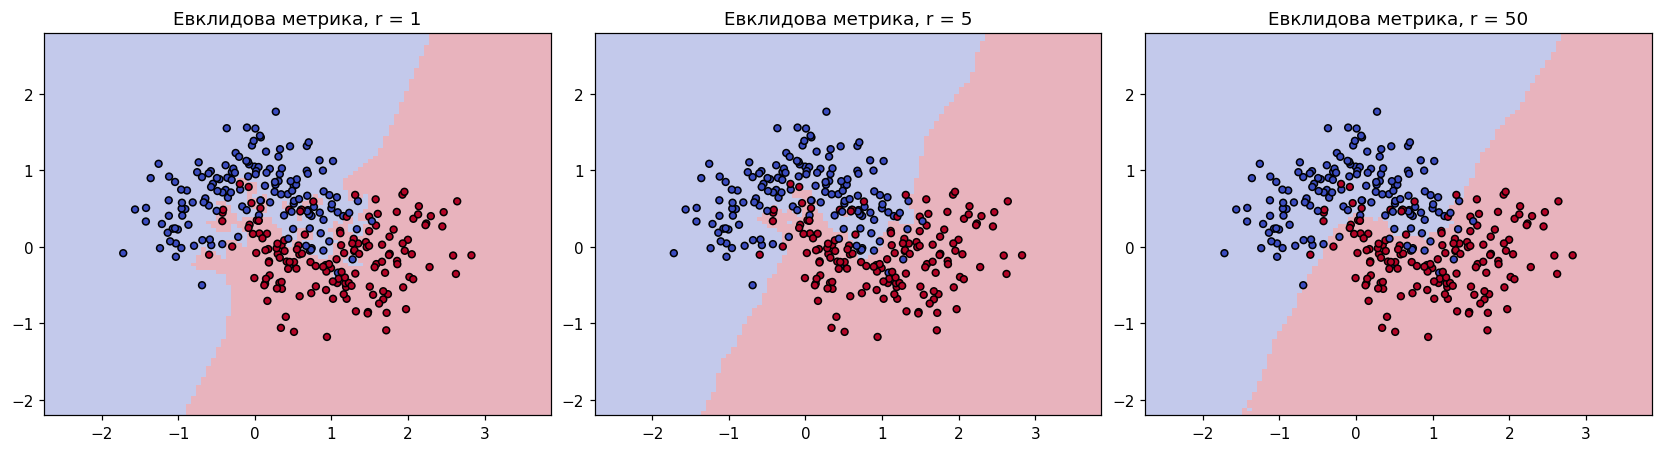

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.datasets import make_moons
from sklearn.inspection import DecisionBoundaryDisplay

X_knn, y_knn = make_moons(n_samples=300, noise=0.3, random_state=42)
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for ax, r in zip(axes, [1, 5, 50]):
    clf = KNeighborsClassifier(n_neighbors=r, metric="euclidean", weights="uniform",
                               algorithm="brute").fit(X_knn, y_knn)
    DecisionBoundaryDisplay.from_estimator(
        clf, X_knn, ax=ax, response_method="predict", plot_method="pcolormesh",
        alpha=0.3, cmap="coolwarm"
    )
    ax.scatter(X_knn[:, 0], X_knn[:, 1], c=y_knn, cmap="coolwarm", edgecolor="k", s=20)
    ax.set_title(f"Евклидова метрика, r = {r}")
plt.show()

<details>
<summary><b>Ядерное сглаживание</b></summary>

**Ядерное сглаживание.** Чтобы вклад наблюдения плавно убывал с расстоянием до запроса, зададим веса через функцию $K$ и ширину окна $h>0$:

$$w_i(x)=K\!\left(\frac{\rho(x,x_i)}{h}\right),\qquad i=1,\ldots,n.$$

Например, для гауссова ядра $K(u)=\exp(-u^2/2)$ существенный вклад дают объекты на расстояниях порядка $h$. Малое $h$ выделяет узкую окрестность запроса; увеличение $h$ усиливает сглаживание.

Для классификации получаем голосование с ядерными весами — метод парзеновского окна:

$$a(x)=\arg\max_{c\in\mathcal Y}\sum_{i=1}^{n}
K\!\left(\frac{\rho(x,x_i)}{h}\right)\mathbb I[y_i=c].$$

</details>

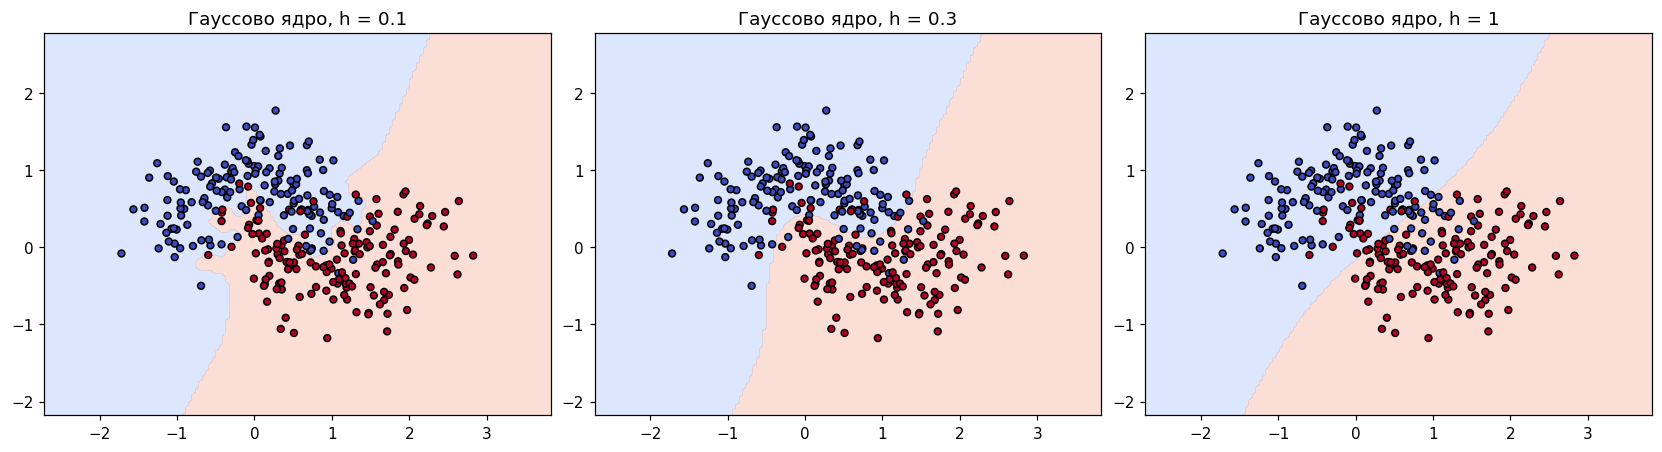

In [ ]:
grid_x, grid_y = np.meshgrid(
    np.linspace(X_knn[:, 0].min() - 1, X_knn[:, 0].max() + 1, 150),
    np.linspace(X_knn[:, 1].min() - 1, X_knn[:, 1].max() + 1, 150),
)
grid_points = np.column_stack([grid_x.ravel(), grid_y.ravel()])
squared_distances = np.sum(
    (grid_points[:, None, :] - X_knn[None, :, :]) ** 2, axis=2,
)
# Common scaling of each row preserves the weighted vote.
squared_distances -= squared_distances.min(axis=1, keepdims=True)
class_indicators = np.eye(2)[y_knn]

fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for ax, h in zip(axes, [0.1, 0.3, 1.0]):
    kernel_weights = np.exp(-squared_distances / (2 * h ** 2))
    class_scores = kernel_weights @ class_indicators
    predictions = class_scores.argmax(axis=1).reshape(grid_x.shape)
    ax.contourf(grid_x, grid_y, predictions, levels=[-0.5, 0.5, 1.5],
                alpha=0.3, cmap="coolwarm")
    ax.scatter(X_knn[:, 0], X_knn[:, 1], c=y_knn, cmap="coolwarm",
               edgecolor="k", s=20)
    ax.set_title(f"Гауссово ядро, h = {h:g}")
plt.show()


**Евклидовы окрестности.** Пусть объекты $x_i\in S$ независимо выбраны из равномерного распределения на кубе:

$$x_i\sim\mathcal U([-1,1]^d).$$

Для запроса $x=0$ рассмотрим евклидову окрестность радиуса $1$. В одномерном случае она совпадает с отрезком $[-1,1]$, в двухмерном — является кругом, вписанным в квадрат $[-1,1]^2$. Вероятность попадания объекта в эту окрестность равна отношению объёма единичного шара к объёму куба:

$$\mathbb P(\|x_i\|_2\leq1)
=\frac{V_d(1)}{2^d}
=\frac{\pi^{d/2}}{2^d\Gamma(d/2+1)}
\xrightarrow[d\to\infty]{}0, \qquad\Gamma(m+1)=m!.$$


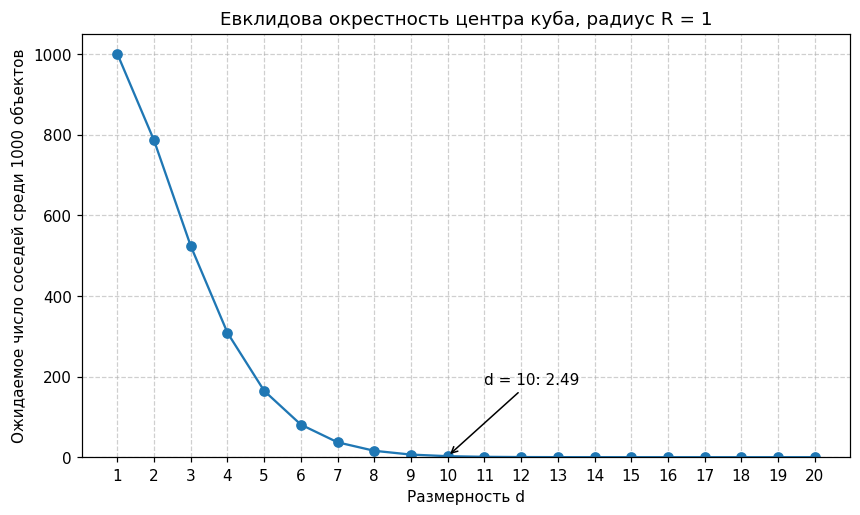

In [ ]:
from math import gamma

ball_dimensions = np.arange(1, 21)
expected_neighbors = np.array([
    1000 * np.pi ** (d / 2) / (2.0 ** d * gamma(d / 2 + 1))
    for d in ball_dimensions
])

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(ball_dimensions, expected_neighbors, marker="o")
ax.annotate(
    f"d = 10: {expected_neighbors[9]:.2f}",
    xy=(10, expected_neighbors[9]),
    xytext=(11, 180),
    arrowprops={"arrowstyle": "->"},
)
ax.set_xticks(ball_dimensions)
ax.set_ylim(0, 1050)
ax.set_xlabel("Размерность d")
ax.set_ylabel("Ожидаемое число соседей среди 1000 объектов")
ax.set_title("Евклидова окрестность центра куба, радиус R = 1")
ax.grid(linestyle="--", alpha=0.6)
plt.show()


### Итог

<details>
<summary><b>Достоинства</b></summary>

- Не требует итерационной оптимизации при обучении: достаточно сохранить размеченную выборку и выбрать параметры поиска соседей.

</details>

<details>
<summary><b>Недостатки</b></summary>

- Для классификации нужны размеченная выборка и заранее заданный набор классов.
- Нужно выбирать число соседей $r$, расстояние и веса; для ядерного сглаживания — ширину окна $h$. Слишком узкая окрестность повышает чувствительность к шуму, слишком широкая смешивает разные области данных.
- Масштаб и неинформативные признаки влияют на выбор соседей; в высокой размерности близких обучающих примеров может оказаться мало.
- При большой обучающей выборке поиск соседей для каждого запроса может быть затратным: полный перебор требует $\mathcal O(nd)$ на вычисление расстояний.

</details>

## Задача кластеризации

Кластеризация является методом обучения без учителя и распространенным методом статистического анализа данных, используемым во многих областях. В частности, используется при составлении портретов пользователей, поиске аномалий.

Исчерпывающий обзор существующих методов кластеризации представлен на [странице](https://scikit-learn.org/stable/modules/clustering.html) scikit-learn

<img src="src/clustering_intro_banner.png" width="800px">

## К-средних (k-means)

### Схема алгоритма

<details>
<summary><b>Описание алгоритма</b></summary>

$$S=\{x_1,\ldots,x_n\}\subset\mathbb R^d,\qquad
T=\{z_1,\ldots,z_k\}\subset\mathbb R^d.$$

Задача оптимизации для евклидовой метрики:

$$\min_{\substack{T\subset\mathbb R^d\\|T|=k}}
\operatorname{cost}(S,T),\qquad
\operatorname{cost}(S,T)=\sum_{x\in S}\min_{z\in T}\|x-z\|_2^2.$$

1. Выберем начальные центры $z_1^{(0)},\ldots,z_k^{(0)}$.
2. На итерации $t\geq1$ отнесём объекты к ближайшим центрам:

   $$C_j^{(t)}=\left\{x\in S:j=\arg\min_{1\leq l\leq k}\|x-z_l^{(t-1)}\|_2^2\right\},
   \qquad j=1,\ldots,k.$$

   Равенства разрешаем по фиксированному правилу.

3. Для каждого непустого кластера пересчитаем центр:

   $$z_j^{(t)}=\frac1{|C_j^{(t)}|}\sum_{x\in C_j^{(t)}}x.$$

   Для пустых кластеров заново инициализируем центры.

4. Остановимся при $\max_{1\leq j\leq k}\|z_j^{(t-1)}-z_j^{(t)}\|_2<\varepsilon$.

</details>

1. Визуализация работы [K-means](https://www.naftaliharris.com/blog/visualizing-k-means-clustering/)
2. Документация [KMeans](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html)

### k-means++

<details>
<summary><b>Описание инициализации</b></summary>

Первый центр $z_1\in S$ выбирается равномерно. Пусть уже выбраны центры $T_i=\{z_1,\ldots,z_i\}$. Следующий центр выбирается из $S$ с вероятностью

$$D_i(x)^2=\min_{z\in T_i}\|x-z\|_2^2,\qquad
\mathbb P(z_{i+1}=x\mid T_i)=\frac{D_i(x)^2}{\sum_{u\in S}D_i(u)^2}.$$

Повторяем до выбора $k$ центров, затем выполняем обычные шаги K-means.

</details>

### Работа алгоритма

In [ ]:
def create_clusters():
    np.random.seed(123)
    X1 = np.random.randn(1000,2)
    X2 = np.random.randn(1000,2) - np.array([10,1])
    X3 = np.random.randn(1000,2) - np.array([1,10])
    X = np.vstack((X1,X2,X3))
    y = np.array([1]*1000 + [2]*1000 + [3]*1000)
    return X, y

X, y = create_clusters()

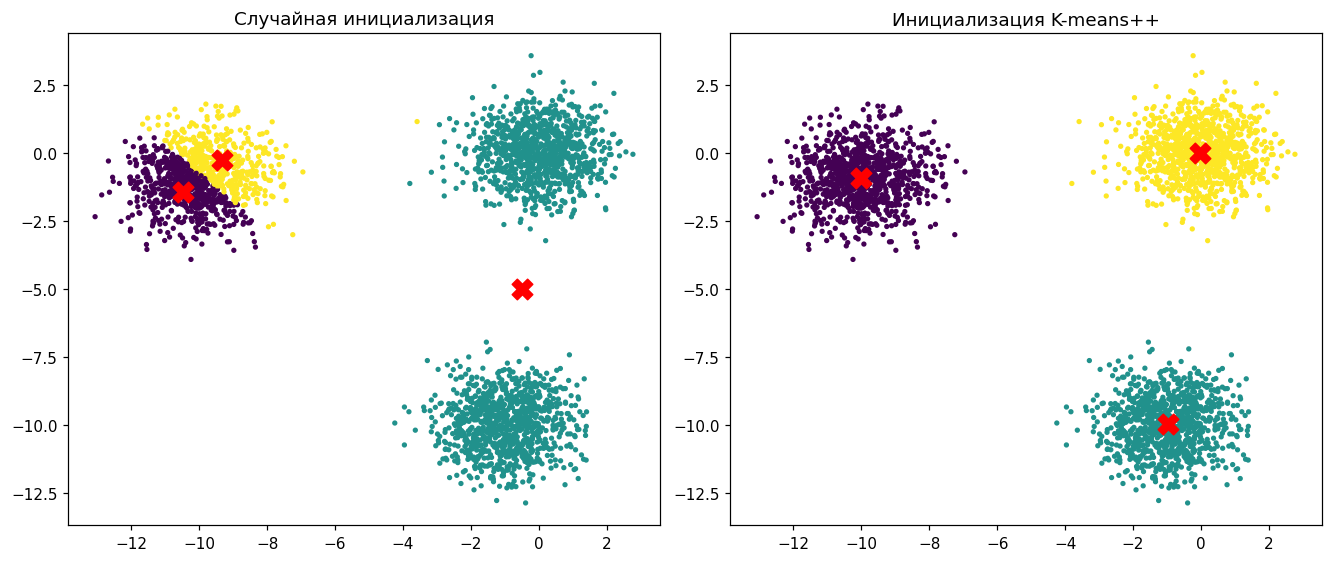

In [ ]:
from sklearn.cluster import KMeans

X_km = X.copy()
seed = 2
fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
for ax, init, title in zip(
    axes,
    ["random", "k-means++"],
    ["Случайная инициализация", "Инициализация K-means++"],
):
    km = KMeans(
        n_clusters=3, init=init, n_init=1, random_state=seed,
    ).fit(X_km)
    ax.scatter(X_km[:, 0], X_km[:, 1], c=km.labels_, s=6, cmap="viridis")
    ax.scatter(*km.cluster_centers_.T, c="red", marker="X", s=180)
    ax.set_title(title)
plt.show()


Посмотрим, что будет происходить, если мы не угадали с числом кластеров.

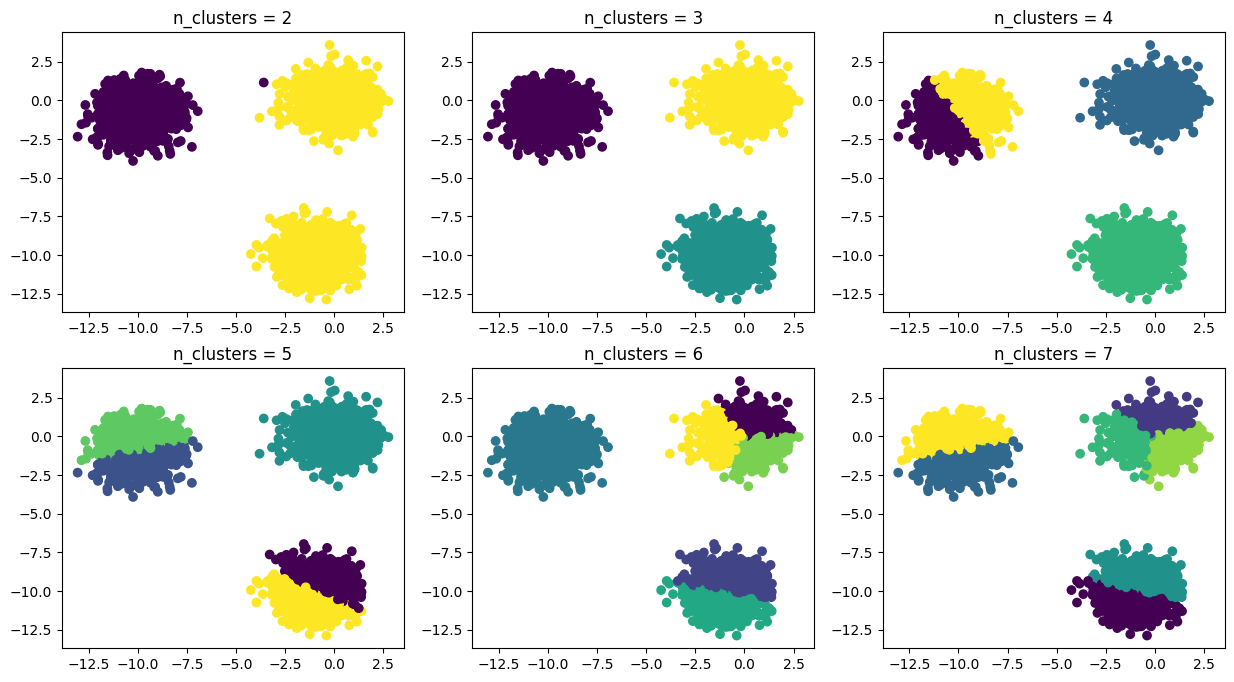

In [ ]:
plt.figure(figsize= (15,8))
for n_c in range(2,8):
    k_means = KMeans(n_clusters = n_c)
    k_means = k_means.fit(X)
    clusters = k_means.predict(X)
    plt.subplot(2,3,n_c - 1)
    plt.scatter(X[:,0], X[:,1], c = clusters)
    plt.title('n_clusters = {}'.format(n_c))

plt.show()

<details>
<summary><b>Почему в K-means границы между кластерами линейные?</b></summary>

При фиксированных центрах $z_1,\ldots,z_k$ условие предпочтения центра $z_i$ центру $z_j$:

$$\|x-z_i\|_2^2\leq\|x-z_j\|_2^2
\iff 2(z_j-z_i)^\top x\leq\|z_j\|_2^2-\|z_i\|_2^2.$$

Это полупространство. Область $i$-го кластера — пересечение таких полупространств по всем $j\ne i$, поэтому она выпукла, а её границы состоят из частей гиперплоскостей.

</details>

### Итог

<details>
<summary><b>Достоинства</b></summary>

- Сложность одной итерации $\mathcal O(nkd)$: при небольших $k$ и $d$ затраты растут линейно с числом объектов.
- Для отнесения нового объекта к кластеру достаточно сравнить его с $k$ центрами.

</details>

<details>
<summary><b>Недостатки</b></summary>

- Результат зависит от начальных центров. K-means++ снижает риск неудачной инициализации.
- Число кластеров $k$ нужно задать заранее.
- Кластеры задаются близостью к центрам: такая модель не описывает, например, две вложенные дуги.
- Масштаб признаков и выбросы влияют на расстояния и положение средних.

</details>

## DBSCAN

DBSCAN (Density-based spatial clustering of applications with noise) - это алгоритм, основанный на плотности: группирует вместе объекты, которые расположены близко, и помечает как выбросы те, что находятся в областях с малой плотностью.

### Схема алгоритма

Для выполнения кластеризации DBSCAN объектам (точкам) выборки присваивается 1 из 4 типов:

1.   Точка $p$ является *основной* точкой, если по меньшей мере `min_samples` точек находятся на расстоянии, не превосходящем `eps` от неё.

    - Уточнение: сама точка p является собственным соседом.

2. Точка $q$ *прямо достижима* из $p$, если $\rho(q, p) \leqslant \varepsilon$ и $p$ - основная точка. Обозначим $p \rightarrow q$.
3. Точка $q$ *достижима* из $p$, если имеется путь $p = p_1 \rightarrow \ldots \rightarrow p_n = q$. Обозначим $p \rightrightarrows q$.
4. Оставшиеся точки считаются *выбросами*

**Следствия:**
1.   Типы 1-3 являются вложенными: $p$ - основная $⇒$ $p \rightarrow p$ $⇒$ $p \rightrightarrows p$.
2.  Тогда *выбросами* можно считать точки, *не достижимые* ни из одной основной.
3. $p \rightrightarrows q$, $\;\not\!\!\!\implies$ $q \rightrightarrows p$. Таким образом *достижимость* не является симметричным отношением.

Рассмотрим следующий пример с `min_samples=4`:

<img src="src/dbscan_illustration.png" width="700px">

1. Красные точки являются основными: область с радиусом `eps` , окружающая эти точки, содержит по меньшей мере 4 точки (включая саму точку).
2. $A \rightrightarrows B$, $A \rightrightarrows C$, $B \not\rightrightarrows A$, $C \not\rightrightarrows A$.
3. $N$ является точкой шума.

### Порядок выполнения DBSCAN

Задаём $\varepsilon$ и `min_samples`. Изначально все точки необработаны.

1. Берём любую необработанную точку $p$, отмечаем её обработанной и находим её $\varepsilon$-окрестность.
2. Если $p$ **не основная**, предварительно отмечаем её как шум и возвращаемся к шагу 1. Позже она может попасть в кластер как граничная.
3. Если $p$ **основная**, создаём новый кластер. Включаем в него $p$ и её соседей, ещё не принадлежащих другому кластеру. Необработанных соседей добавляем в очередь без повторов.
4. Достаём из очереди точку $q$, отмечаем её обработанной и находим её $\varepsilon$-окрестность.
5. Если $q$ **основная**, включаем её соседей в текущий кластер по тому же правилу, а необработанных добавляем в очередь. Если **не основная**, она остаётся в кластере, но очередь не расширяет.
6. Повторяем шаги 4–5, пока очередь не опустеет. Текущий кластер закончен.
7. Возвращаемся к шагу 1. Завершаем, когда все точки обработаны.


[Визуализация](https://www.naftaliharris.com/blog/visualizing-dbscan-clustering/) DBSCAN.

### Работа алгоритма

Документация [DBSCAN](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html)

In [ ]:
from sklearn.cluster import DBSCAN

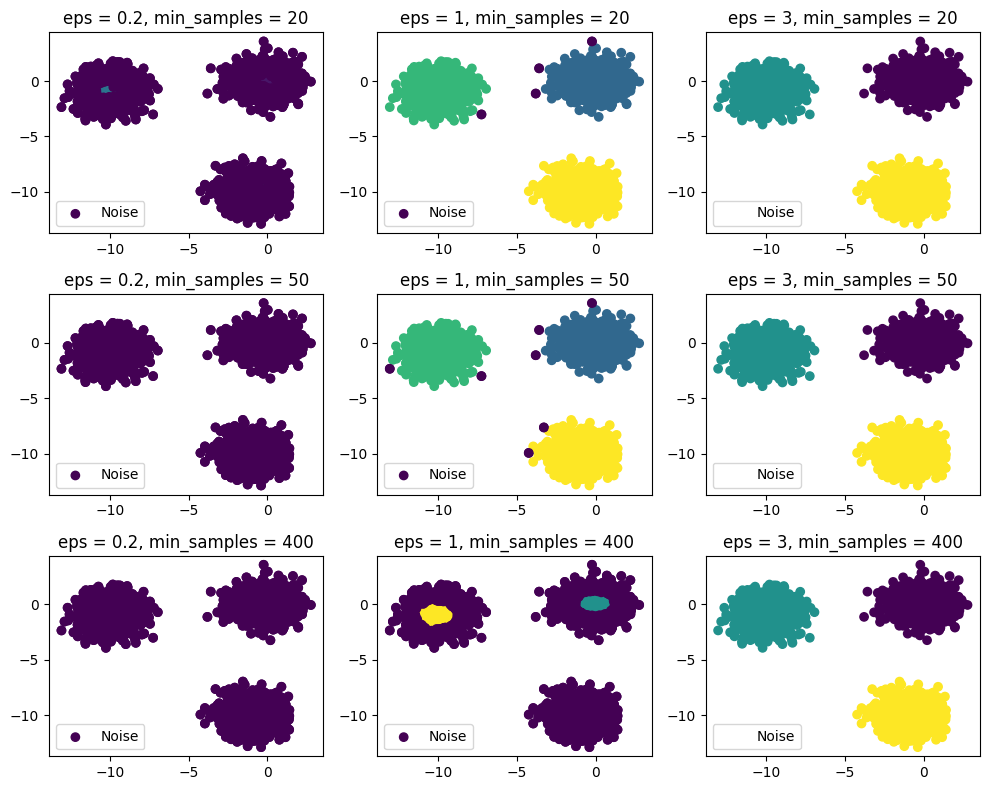

In [ ]:
plt.figure(figsize=(10, 8))
i = 1
for samples in [20, 50, 400]:
    for e in [0.2, 1, 3]:
        dbscan = DBSCAN(eps=e, min_samples=samples)
        clusters = dbscan.fit_predict(X)
        plt.subplot(3, 3, i)  # 3x3 grid
        plt.scatter(X[:, 0], X[:, 1], c=clusters)
        noise = X[clusters == -1]
        plt.scatter(noise[:, 0], noise[:, 1], c=[-1 for _ in range(len(noise))], label='Noise')
        plt.title('eps = {}, min_samples = {}'.format(e, samples))
        plt.legend()
        i += 1

plt.tight_layout()  # Adjust the spacing between subplots
plt.show()

В отличие от K-средних, метод применим и для нелинейно-разделимых кластеров

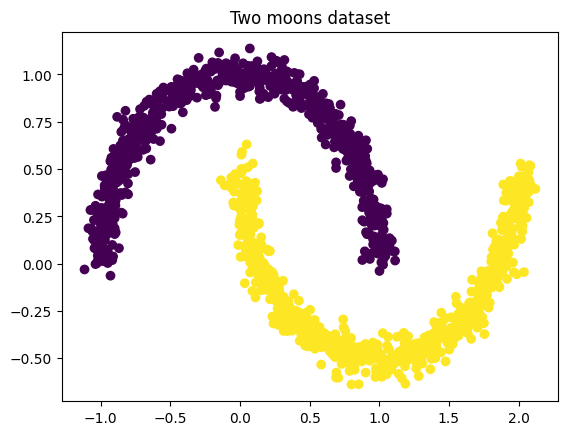

In [ ]:
from sklearn import datasets

X_moon, y_moon = datasets.make_moons(n_samples=1500, noise=.05, random_state=42)
plt.scatter(X_moon[:, 0], X_moon[:, 1], c=y_moon, cmap='viridis')
plt.title(f"Two moons dataset")
plt.show()

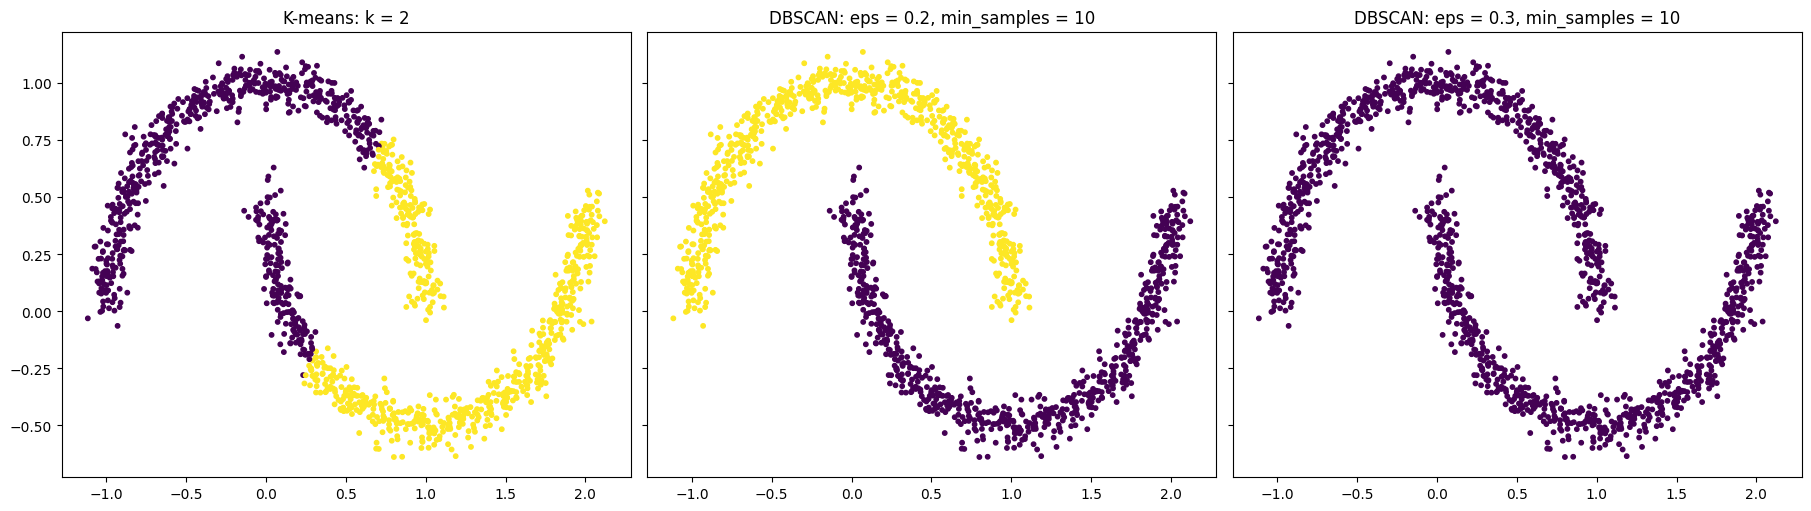

In [ ]:
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_moon)

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True,
                         constrained_layout=True)
axes[0].scatter(X_moon[:, 0], X_moon[:, 1], c=kmeans_labels, cmap="viridis", s=10)
axes[0].set_title("K-means: k = 2")
for ax, eps in zip(axes[1:], [0.2, 0.3]):
    dbscan = DBSCAN(eps=eps, min_samples=10)
    dbscan_labels = dbscan.fit_predict(X_moon)
    clustered = dbscan_labels != -1
    ax.scatter(X_moon[clustered, 0], X_moon[clustered, 1],
               c=dbscan_labels[clustered], cmap="viridis", s=10)
    if (~clustered).any():
        ax.scatter(X_moon[~clustered, 0], X_moon[~clustered, 1],
                   c="black", marker="x", s=15, label="Шум")
        ax.legend()
    ax.set_title(f"DBSCAN: eps = {eps}, min_samples = 10")
plt.show()

### Итог

<details>
<summary><b>Достоинства</b></summary>

1. В отличие от К-средних не требует указания количества кластеров $k$.
2. Может работать с нелинейно-разделимыми кластерами.
3. Имеет понятие шума и устойчив к выбросам

</details>

<details>
<summary><b>Недостатки</b></summary>

1. Относительно К-средних, алгоритм вычислительно-затратнее (в худшем случае сложность алгоритма $\mathcal{O}(n^2)$).
2. Аналогично К-средним, разделение осуществляется на основе *расстояния*. Евклидова метрика обладает [проклятием размерности](https://ru.wikipedia.org/wiki/%D0%9F%D1%80%D0%BE%D0%BA%D0%BB%D1%8F%D1%82%D0%B8%D0%B5_%D1%80%D0%B0%D0%B7%D0%BC%D0%B5%D1%80%D0%BD%D0%BE%D1%81%D1%82%D0%B8).
3. Если данные и масштаб не вполне хорошо поняты, выбор осмысленного порога расстояния $\varepsilon$ может оказаться трудным.
4. Алгоритм плохо разделяет кластеры различной плотности.

</details>

## Иерархическая кластеризация

*Иерархическая кластеризация* — множество алгоритмов кластеризации, направленных на создание иерархии вложенных разбиений исходного множества объектов. Выделяют два класса методов иерархической кластеризации:
* *Агломеративные методы*: от меньших кластеров к большим (от листьев к стволу дерева);
* *Дивизионные методы*: от больших кластеров к меньшим (от ствола к листьям дерева).

Для однозначности, будем рассматривать *агломеративные методы*.

### Схема метода

Алгоритмы иерархической кластеризации можно свести к следующей процедуре *слияния* кластеров:
1. В начальный момент времени каждый объект содержится в собственном кластере
2. Для слияния кластеров необходимо уметь вычислять расстояние между кластерами
* Расстояние между одноэлементными кластерами определяется через расстояние между объектами:
$$ R(\{x\}, \{y\}) =  \rho(x, y). $$
   
* Расстояние между кластерами $R(U, V)$ определяется различными функциями.
3. Объединяющиеся кластеры выбираются в соответствии с наименьшим расстоянием: $U \cup \arg\min_{V}R(U, V)$.
4. Процедура повторяется до объединения всех кластеров в один.

**Функции расстояния между кластерами:**
* Метод одиночной связи:
$$ R_{\min}(U, V) = \min_{u\in U, v\in V} \rho(u, v);$$
* Метод полной связи:
$$ R_{\max}(U, V) = \max_{u\in U, v\in V} \rho(u, v);$$
* Метод средней связи:
$$ R_{\text{avg}}(U, V) = \dfrac{1}{|U|\cdot |V|}\sum_{u\in U}\sum_{v\in V}\rho(u, v);$$
* Центроидный метод:
$$ R_{\text{c}}(U, V) = \rho^2\left(\sum_{u\in U}\dfrac{u}{|U|}, \sum_{v\in V}\dfrac{v}{|V|}\right);$$
* Метод Уорда:
$$ \dfrac{|U|\cdot |V|}{|U| + |V|}\rho^2\left(\sum_{u\in U}\dfrac{u}{|U|}, \sum_{v\in V}\dfrac{v}{|V|}\right).$$

### Работа алгоритма

In [ ]:
from sklearn import datasets

def iris_subset(num_samples=30):
    iris = datasets.load_iris()
    indices = np.random.RandomState(42).choice(len(iris.data), size=num_samples, replace=False)
    return iris, iris.data[indices], iris.target[indices]

iris, X_iris, y_iris = iris_subset()


Документация [AgglomerativeClustering](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.AgglomerativeClustering.html)

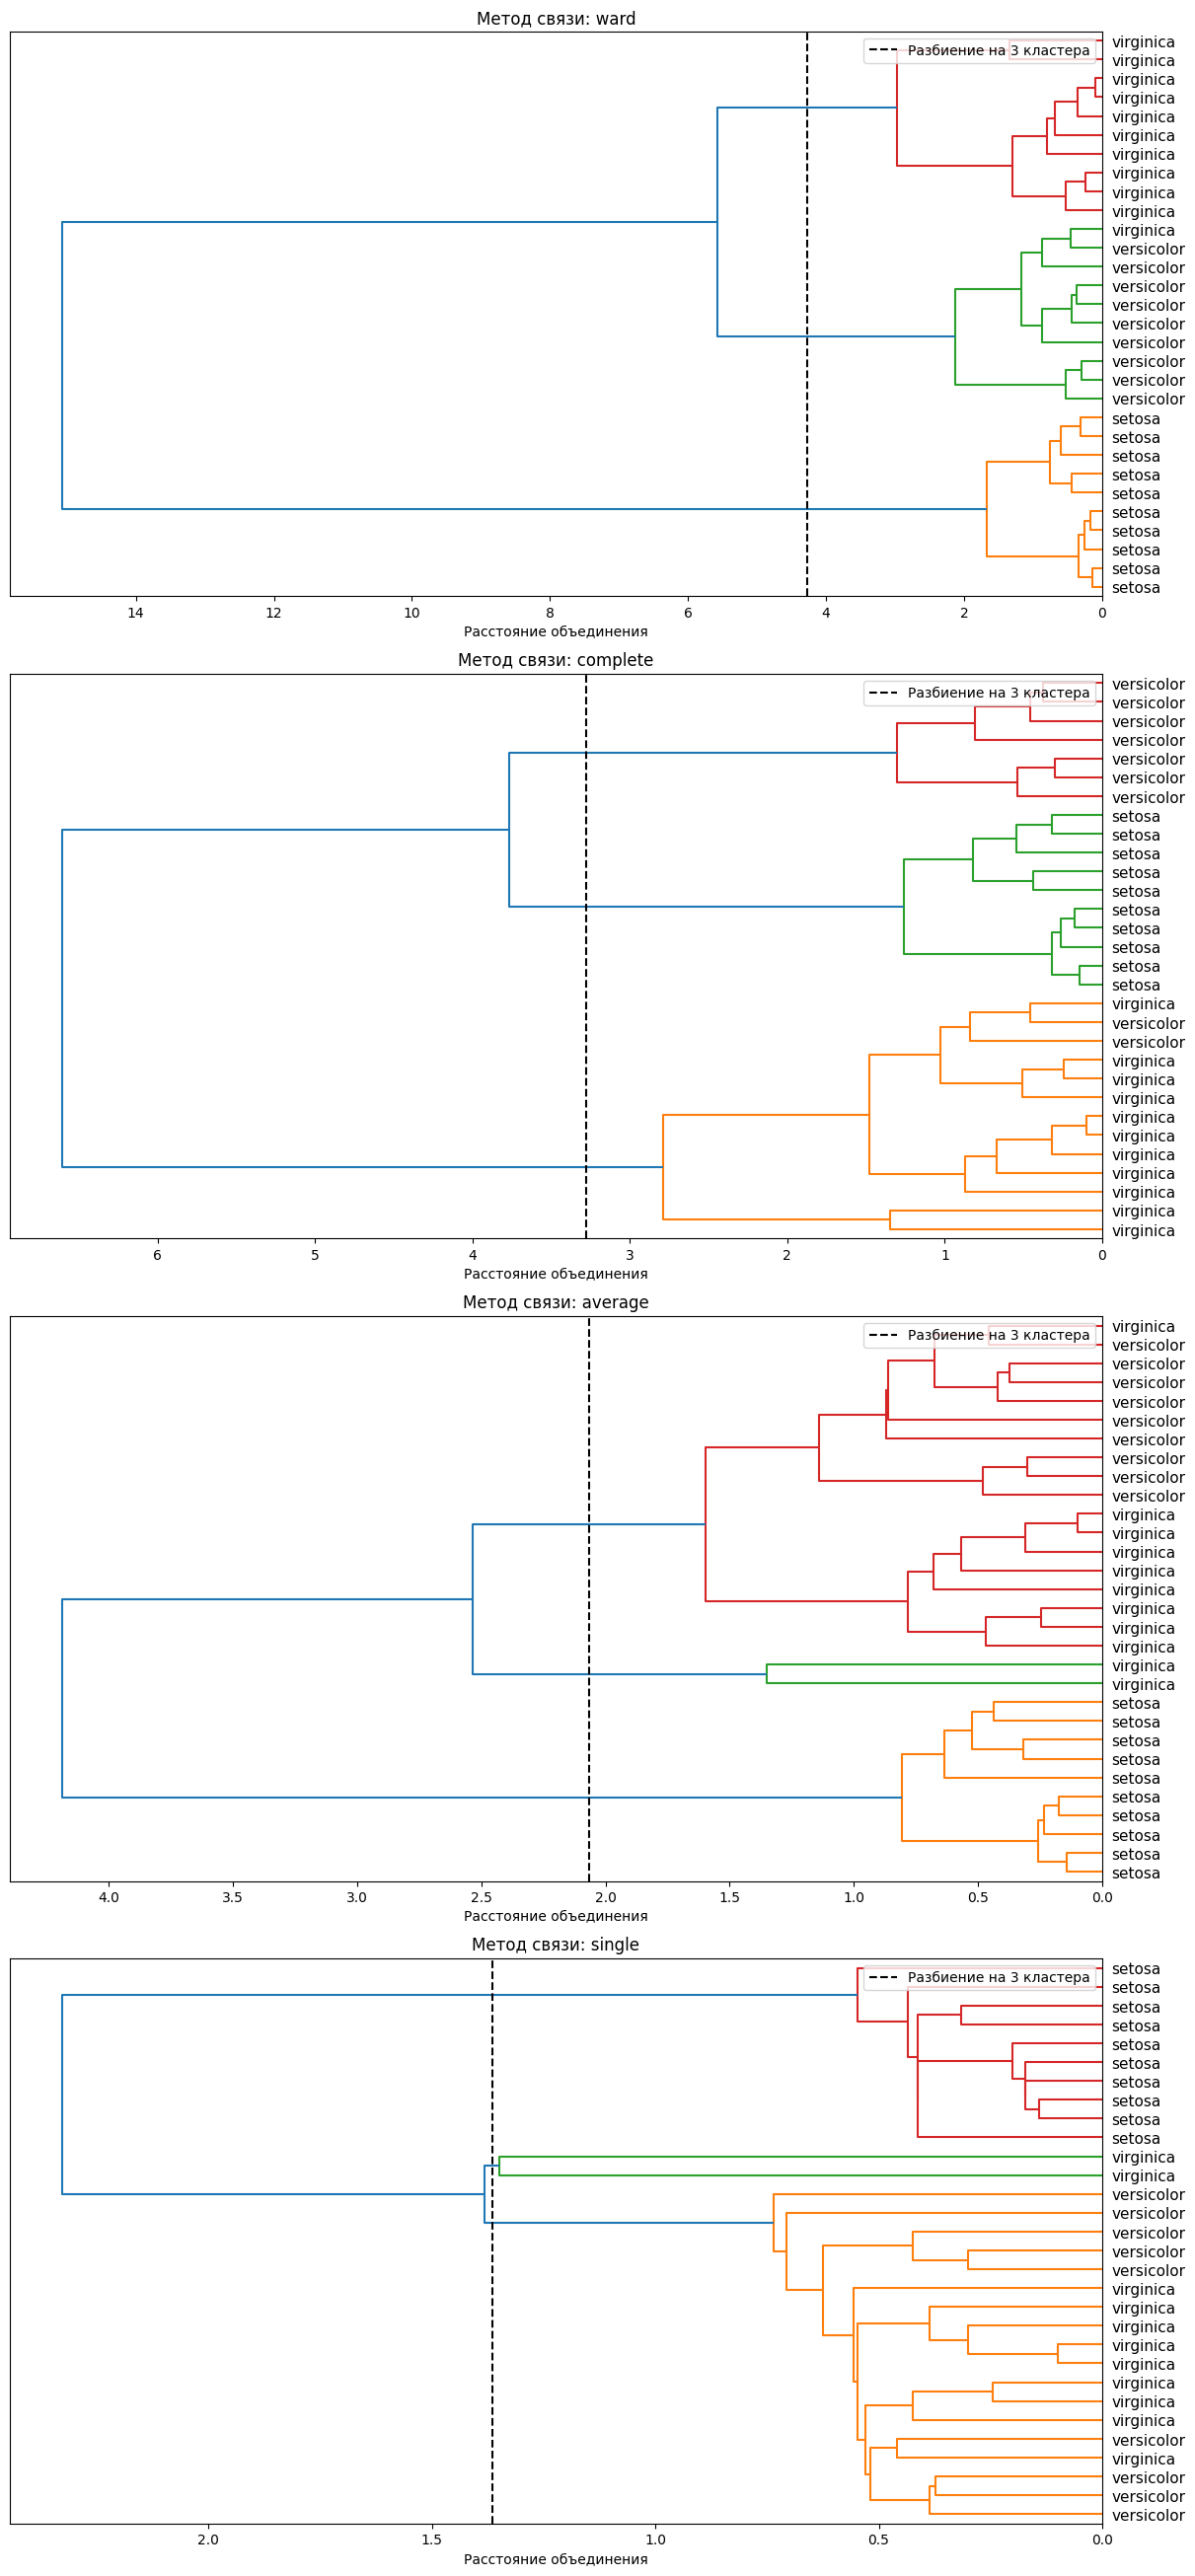

In [ ]:
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram

linkage_methods = ["ward", "complete", "average", "single"]
fig, axes = plt.subplots(4, 1, figsize=(12, 26), constrained_layout=True)

for ax, method in zip(axes, linkage_methods):
    model = AgglomerativeClustering(
        n_clusters=None, linkage=method, distance_threshold=0,
        metric="euclidean", compute_distances=True,
    ).fit(X_iris)

    counts = np.ones(2 * len(X_iris) - 1)
    for i, children in enumerate(model.children_):
        counts[len(X_iris) + i] = counts[children].sum()
    linkage_matrix = np.column_stack([
        model.children_, model.distances_, counts[len(X_iris):],
    ])

    cut_height = (model.distances_[-3] + model.distances_[-2]) / 2
    dendrogram(
        linkage_matrix, labels=[iris.target_names[k] for k in y_iris],
        orientation="left", leaf_font_size=11,
        color_threshold=cut_height, ax=ax,
    )
    ax.axvline(cut_height, color="black", linestyle="--", label="Разбиение на 3 кластера")
    ax.set_title(f"Метод связи: {method}")
    ax.set_xlabel("Расстояние объединения")
    ax.legend()
plt.show()



Для определения числа кластеров находится интервал максимальной длины $|R_{t+1} - R_t|$. В качестве итоговых кластеров выдаются кластеры, полученные на шаге t.

Однако, когда число кластеров заранее неизвестно и объектов в выборке не очень много, бывает полезно изучить дендрограмму целиком.

В иерархическую кластеризацию можно добавить априорную информацию о природе данных. Она определяется через *матрицу связей*, задающих отношение между объектами выборки.

Безусловная работа алгоритма

<img src="src/clusters.png" width="400px">

<img src="src/hierarchical_clustering.png" width="600px">

Матрица связей
$$
A = \begin{pmatrix}
& a & b & c & d & e & f \\
a & \cdot & \cdot& \cdot& \cdot& \cdot & \cdot\\
b & \cdot & \cdot& \cdot& \cdot& \cdot & \cdot\\
c & \cdot & \cdot& \cdot& \cdot& \cdot & \cdot\\
d & \cdot & \cdot& \cdot& \cdot& \cdot & 0.0\\
e & \cdot & \cdot& \cdot& \cdot& \cdot & 0.0\\
f & \cdot & \cdot& \cdot& 0.0& 0.0 & \cdot\\
\end{pmatrix}
$$

Работа алгоритма в случае матрицы связей $A$ и одиночной связью $R_{\min}(U, V)$:

<img src="src/hierarchical_dendrogram.png" width="600px">

Действительно, $R_{\min}(de, f)$ не определена (все элементы внутри кластеров не связаны), а $R_{\min}(bcf, de) = \rho(b, d) < \rho(b, a) = R_{\min}(bcf, a)$, поэтому на 3-м шаге связываем $bcf$ и $de$.

### Итог

<details>
<summary><b>Достоинства</b></summary>

* Может работать в случае нелинейной разделимости.
* Не требует подбора гиперпараметров (в отличие от К-средних и DBSCAN).
* Поддерживает добавление априорной информации о связи в данных.

</details>

<details>
<summary><b>Недостатки</b></summary>

* Вычислительная сложность $\mathcal{O}(n^3)$ и сложность по памяти $\Omega(n^2)$ $⇒$ трудно шкалировать даже для средних наборов данных.

</details>

**Особенности:**
* Дендрограмма становится нечитаемой при умеренном количестве примеров. Соответственно, визуальный анализ для определения количества кластеров затруднён.

## Иерархические методы на основе плотности

### OPTICS

OPTICS (‘Ordering Points To Identify Clustering Structure’) - модификация DBSCAN, поддерживающая кластеризацию с различными плотностями.

#### **Вопрос**

Почему DBSCAN плохо работает с разной плотностью кластеров?

Дело в том, что он содержит унифицированные гиперпараметры `eps` и `min_samples`. Эти параметры задают "масштаб" кластеризации. Если они унифицированы, масштаб для всех кластеров одинаковый.

#### Схема метода

OPTICS вводит 2 понятия:
* *Основное расстояние точки $p$:* Минимальный радиус окружности, необходимый, чтобы точка $p$ стала основной. Если этот радиус больше `eps` (т.е. точка $p$ не является основной), то основное расстояние считается неопределённым. Обозначим $\rho_{\text{core}}(p)$;

* *Достижимое расстояние точки $q$ от точки $p$:* $\rho_{\text{reach}}(q, p) = \max(\rho_{\text{core}}(p), \rho(q, p))$. Если $p$ не является основной точкой, то $\rho_{\text{reach}}(q, p)$ не определена

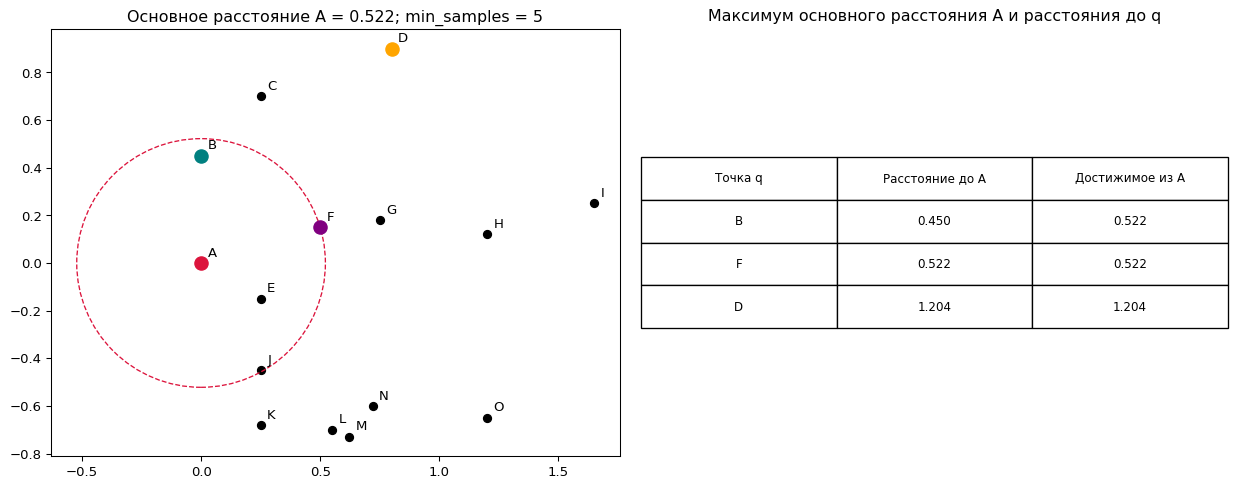

In [ ]:
from sklearn.cluster import OPTICS, cluster_optics_dbscan
from matplotlib.patches import Circle

X_optics_small = np.array([
    [0.00, 0.00], [0.00, 0.45], [0.25, 0.70], [0.80, 0.90],
    [0.25, -0.15], [0.50, 0.15], [0.75, 0.18], [1.20, 0.12],
    [1.65, 0.25], [0.25, -0.45], [0.25, -0.68], [0.55, -0.70],
    [0.62, -0.73], [0.72, -0.60], [1.20, -0.65],
])
optics_names = np.array(list("ABCDEFGHIJKLMNO"))
optics_min_samples = 5
optics_small = OPTICS(min_samples=optics_min_samples, xi=0.1,
                      min_cluster_size=5, max_eps=np.inf).fit(X_optics_small)
optics_distances = np.linalg.norm(
    X_optics_small[:, None, :] - X_optics_small[None, :, :], axis=2,
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
axes[0].scatter(*X_optics_small.T, c="black")
for name, point in zip(optics_names, X_optics_small):
    axes[0].annotate(name, point, xytext=(5, 5), textcoords="offset points")
core_radius = optics_small.core_distances_[0]
axes[0].add_patch(Circle(X_optics_small[0], core_radius, fill=False,
                         linestyle="--", color="crimson"))
for index, color in [(0, "crimson"), (1, "teal"), (5, "purple"), (3, "orange")]:
    axes[0].scatter(*X_optics_small[index], c=color, s=100, zorder=3)
axes[0].set_aspect("equal")
axes[0].set_title(f"Основное расстояние A = {core_radius:.3f}; min_samples = 5")
rows = [
    [optics_names[q], f"{optics_distances[0, q]:.3f}",
     f"{max(core_radius, optics_distances[0, q]):.3f}"]
    for q in [1, 5, 3]
]
axes[1].axis("off")
axes[1].table(cellText=rows, colLabels=["Точка q", "Расстояние до A", "Достижимое из A"],
              cellLoc="center", bbox=[0, 0.3, 1, 0.4])
axes[1].set_title("Максимум основного расстояния A и расстояния до q")
plt.show()

def optics_snapshot(step):
    reach = np.full(len(X_optics_small), np.inf)
    predecessor = np.full(len(X_optics_small), -1)
    processed = np.zeros(len(X_optics_small), dtype=bool)
    for p in optics_small.ordering_[:step]:
        processed[p] = True
        candidates = np.maximum(optics_small.core_distances_[p], optics_distances[p])
        improved = (~processed) & (candidates < reach)
        reach[improved] = candidates[improved]
        predecessor[improved] = p
    return processed, reach, predecessor

def plot_optics_step(step):
    processed, reach, predecessor = optics_snapshot(step)
    current = optics_small.ordering_[step - 1]
    queue = np.flatnonzero((~processed) & np.isfinite(reach))
    queue = queue[np.argsort(reach[queue], kind="stable")]
    fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
    colors = np.where(processed, "lightcoral", "white")
    colors[current] = "turquoise"
    axes[0].scatter(*X_optics_small.T, c=colors, edgecolor="black", s=90)
    for name, point in zip(optics_names, X_optics_small):
        axes[0].annotate(name, point, xytext=(5, 5), textcoords="offset points")
    axes[0].add_patch(Circle(X_optics_small[current], optics_small.core_distances_[current],
                             fill=False, linestyle="--", color="teal"))
    axes[0].set_aspect("equal")
    axes[0].set_title(f"Шаг {step}; текущая точка {optics_names[current]}")
    order_text = " → ".join(optics_names[optics_small.ordering_[:step]])
    axes[0].set_xlabel(f"Порядок: {order_text}")
    axes[1].axis("off")
    if len(queue):
        table_indices = queue
        axes[1].set_title("Очередь после обработки текущей точки")
    else:
        table_indices = optics_small.ordering_[:step]
        axes[1].set_title("Очередь пуста; результат обхода")
    rows = [[optics_names[q], "∞" if not np.isfinite(reach[q]) else f"{reach[q]:.3f}",
             "—" if predecessor[q] < 0 else optics_names[predecessor[q]]]
            for q in table_indices]
    axes[1].table(cellText=rows, colLabels=["Точка", "Достижимое расстояние", "Предшественник"],
                  cellLoc="center", bbox=[0, 0, 1, 0.9])
    plt.show()


График достижимости строится в порядке обхода объектов:
1. Выбираем непросмотренную точку $p$. Для начала нового обхода полагаем $\rho_{\mathrm{reach}}(p)=\infty$.
2. Отмечаем $p$ просмотренной. Если $\rho_{\mathrm{core}}(p)$ определено, для каждого непросмотренного соседа $q$ обновляем

   $$\rho_{\mathrm{reach}}(q)\leftarrow\min\{\rho_{\mathrm{reach}}(q),\max(\rho_{\mathrm{core}}(p),\rho(q,p))\}.$$

3. Следующей выбираем точку с минимальным текущим достижимым расстоянием среди всех кандидатов и повторяем п. 2.
4. Когда кандидатов нет, начинаем новый обход с оставшейся непросмотренной точки. После обработки всех объектов строим график сохранённых достижимых расстояний в порядке обхода.

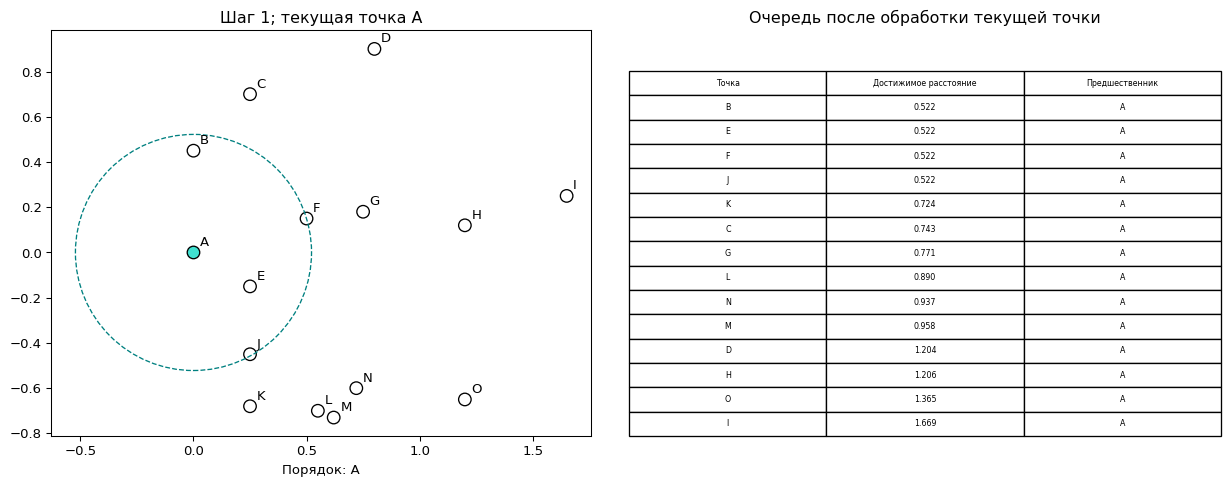

In [ ]:
plot_optics_step(1)


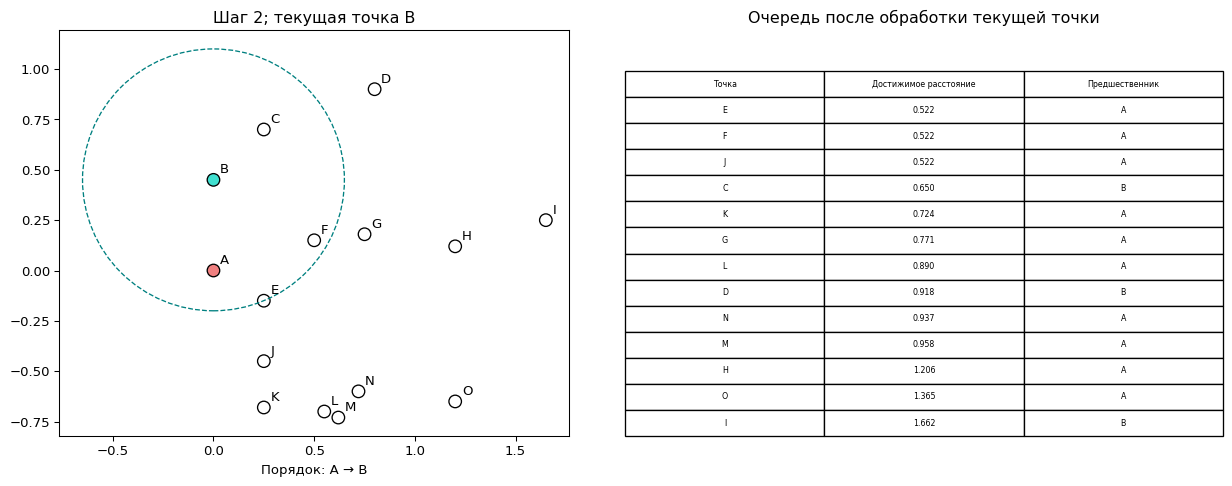

In [ ]:
plot_optics_step(2)


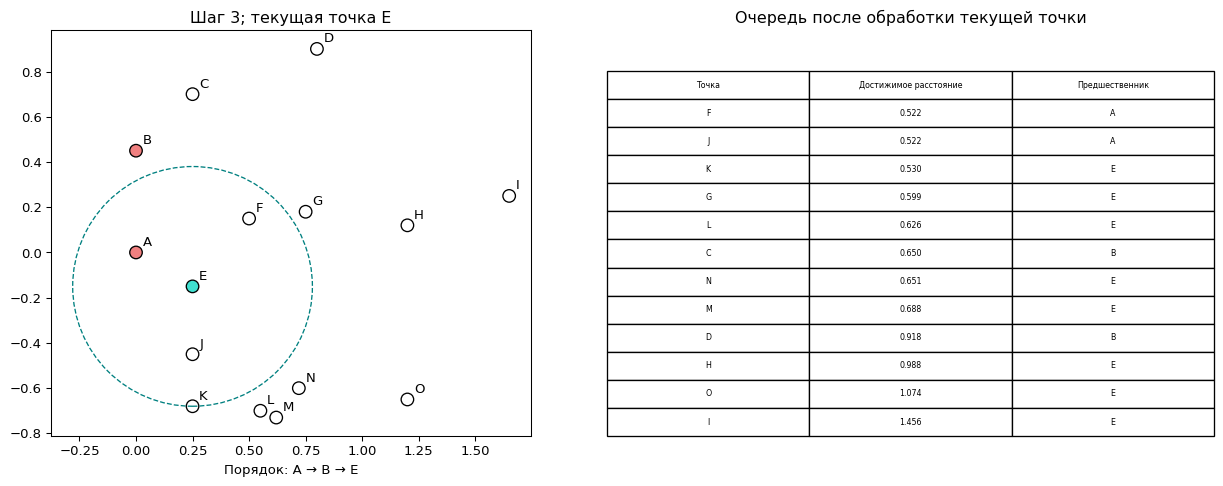

In [ ]:
plot_optics_step(3)


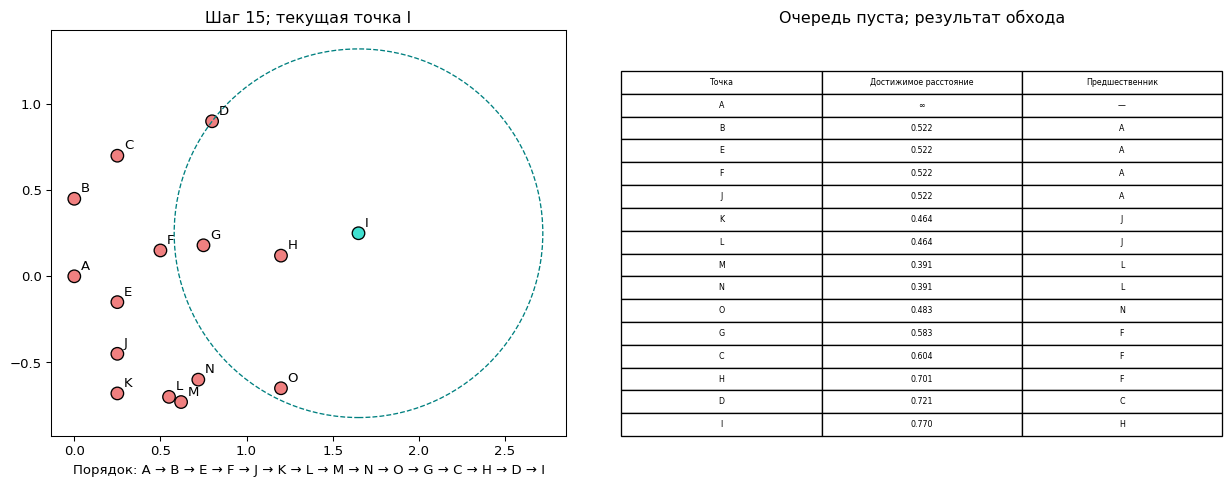

In [ ]:
plot_optics_step(len(X_optics_small))


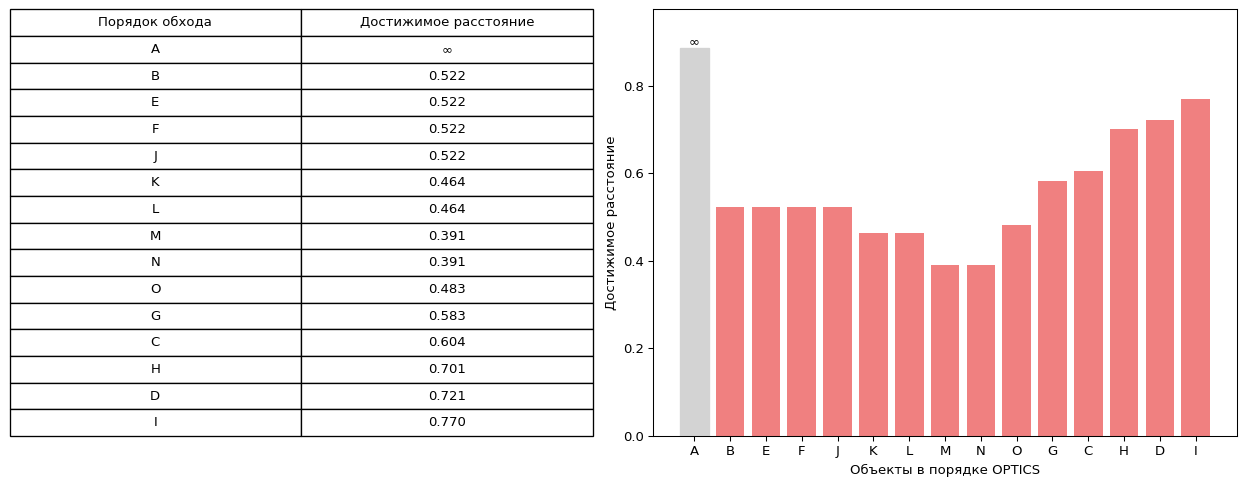

In [ ]:
optics_order = optics_small.ordering_
ordered_reach = optics_small.reachability_[optics_order]
reach_limit = ordered_reach[np.isfinite(ordered_reach)].max() * 1.15
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
rows = [[optics_names[p], "∞" if not np.isfinite(value) else f"{value:.3f}"]
        for p, value in zip(optics_order, ordered_reach)]
axes[0].axis("off")
axes[0].table(cellText=rows, colLabels=["Порядок обхода", "Достижимое расстояние"],
              cellLoc="center", bbox=[0, 0, 1, 1])
bars = axes[1].bar(optics_names[optics_order], np.where(np.isfinite(ordered_reach),
                                                      ordered_reach, reach_limit), color="lightcoral")
for bar, value in zip(bars, ordered_reach):
    if not np.isfinite(value):
        bar.set_color("lightgray")
        bar.set_hatch("//")
        axes[1].text(bar.get_x() + bar.get_width() / 2, reach_limit, "∞", ha="center", va="bottom")
axes[1].set_ylim(0, reach_limit * 1.1)
axes[1].set_xlabel("Объекты в порядке OPTICS")
axes[1].set_ylabel("Достижимое расстояние")
plt.show()


График достижимости позволяет исследовать структуру кластеров на разных уровнях плотности.

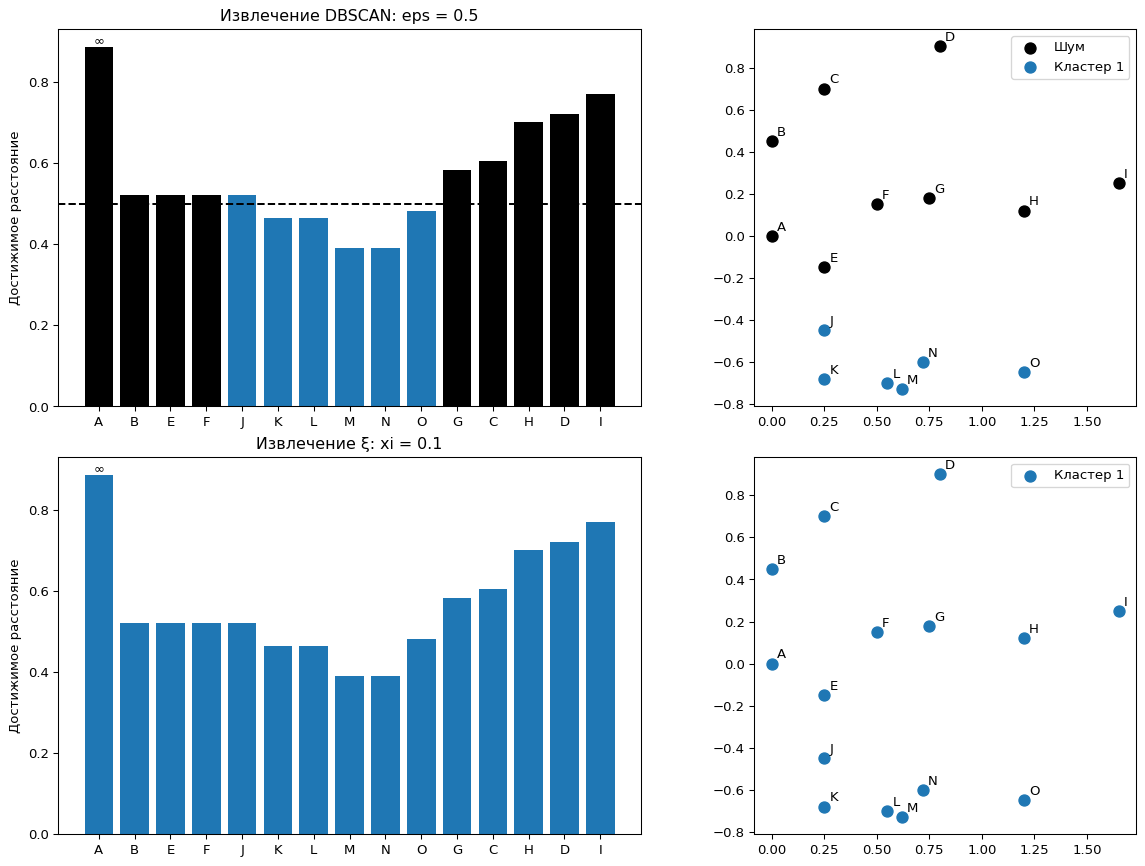

In [ ]:
optics_cut = 0.5
optics_cut_labels = cluster_optics_dbscan(
    reachability=optics_small.reachability_, core_distances=optics_small.core_distances_,
    ordering=optics_small.ordering_, eps=optics_cut,
)
fig, axes = plt.subplots(2, 2, figsize=(13, 9), constrained_layout=True)
for row, (labels, name) in enumerate([
    (optics_cut_labels, "Извлечение DBSCAN: eps = 0.5"),
    (optics_small.labels_, "Извлечение ξ: xi = 0.1"),
]):
    for label in np.unique(labels):
        mask = labels == label
        color = "black" if label == -1 else plt.get_cmap("tab10")(int(label) % 10)
        name_label = "Шум" if label == -1 else f"Кластер {label + 1}"
        axes[row, 1].scatter(*X_optics_small[mask].T, color=color, label=name_label, s=70)
        positions = np.flatnonzero(labels[optics_order] == label)
        axes[row, 0].bar(positions, np.where(np.isfinite(ordered_reach[positions]),
                                            ordered_reach[positions], reach_limit), color=color)
    if row == 0:
        axes[row, 0].axhline(optics_cut, color="black", linestyle="--")
    for name_point, point in zip(optics_names, X_optics_small):
        axes[row, 1].annotate(name_point, point, xytext=(4, 4), textcoords="offset points")
    axes[row, 0].set_xticks(np.arange(len(optics_order)), optics_names[optics_order])
    axes[row, 0].set_ylabel("Достижимое расстояние")
    axes[row, 0].set_title(name)
    axes[row, 0].text(0, reach_limit, "∞", ha="center", va="bottom")
    axes[row, 1].set_aspect("equal")
    axes[row, 1].legend()
plt.show()


#### Работа алгоритма

Документация [OPTICS](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.OPTICS.html)

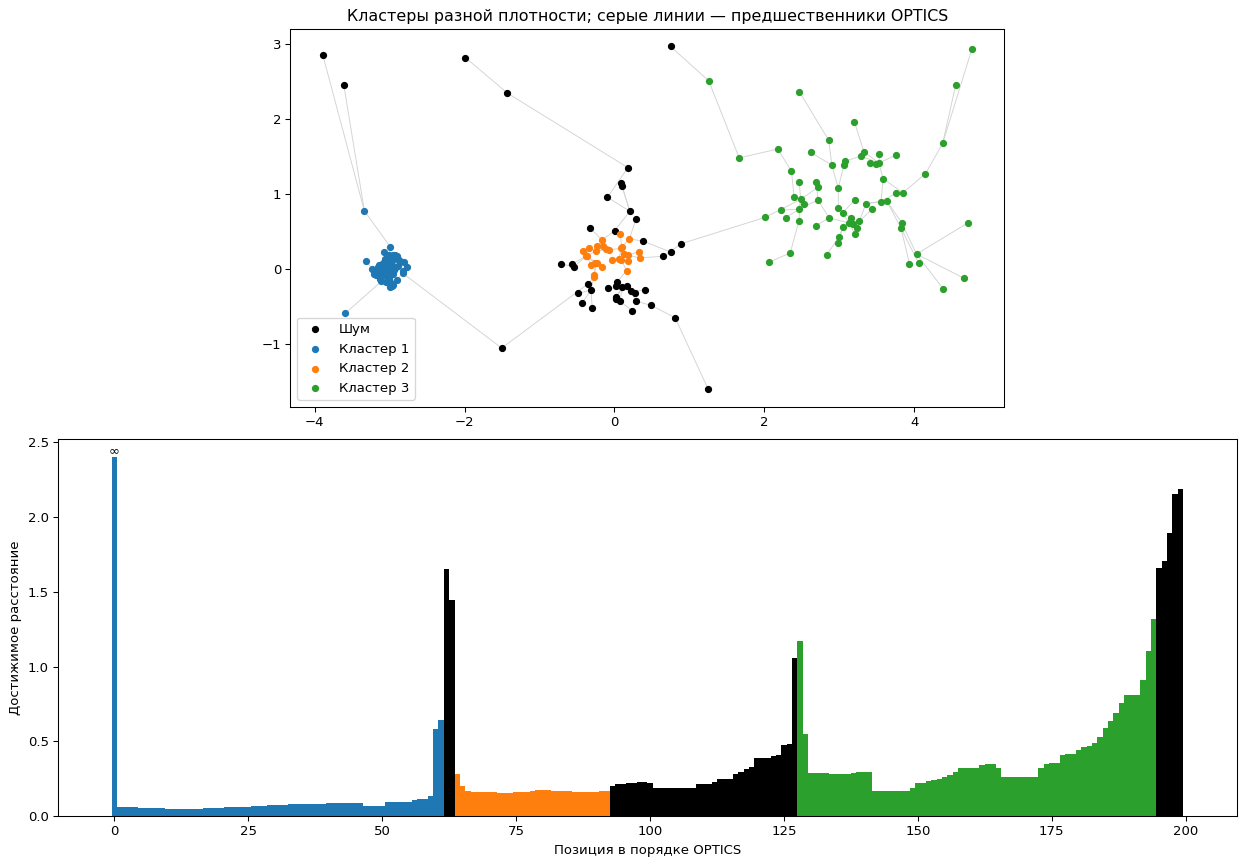

In [ ]:
rng_optics = np.random.RandomState(42)
X_optics_density = np.vstack([
    rng_optics.normal(center, scale, size=(60, 2))
    for center, scale in [((-3, 0), 0.12), ((0, 0), 0.35), ((3, 1), 0.65)]
] + [rng_optics.uniform([-4, -2], [5, 3], size=(20, 2))])
optics_density = OPTICS(min_samples=8, xi=0.1, min_cluster_size=25).fit(X_optics_density)
order_density = optics_density.ordering_
reach_density = optics_density.reachability_[order_density]
display_height = reach_density[np.isfinite(reach_density)].max() * 1.1
fig, axes = plt.subplots(2, 1, figsize=(13, 9), constrained_layout=True)
for point, parent in enumerate(optics_density.predecessor_):
    if parent >= 0:
        axes[0].plot(*X_optics_density[[parent, point]].T, color="lightgray", linewidth=0.7, zorder=0)
for label in np.unique(optics_density.labels_):
    mask = optics_density.labels_ == label
    color = "black" if label == -1 else plt.get_cmap("tab10")(int(label) % 10)
    label_name = "Шум" if label == -1 else f"Кластер {label + 1}"
    axes[0].scatter(*X_optics_density[mask].T, color=color, label=label_name, s=20)
    positions = np.flatnonzero(optics_density.labels_[order_density] == label)
    axes[1].bar(positions, np.where(np.isfinite(reach_density[positions]),
                                    reach_density[positions], display_height), color=color, width=1)
axes[0].set_title("Кластеры разной плотности; серые линии — предшественники OPTICS")
axes[0].legend()
axes[0].set_aspect("equal")
axes[1].text(0, display_height, "∞", ha="center", va="bottom")
axes[1].set_xlabel("Позиция в порядке OPTICS")
axes[1].set_ylabel("Достижимое расстояние")
plt.show()


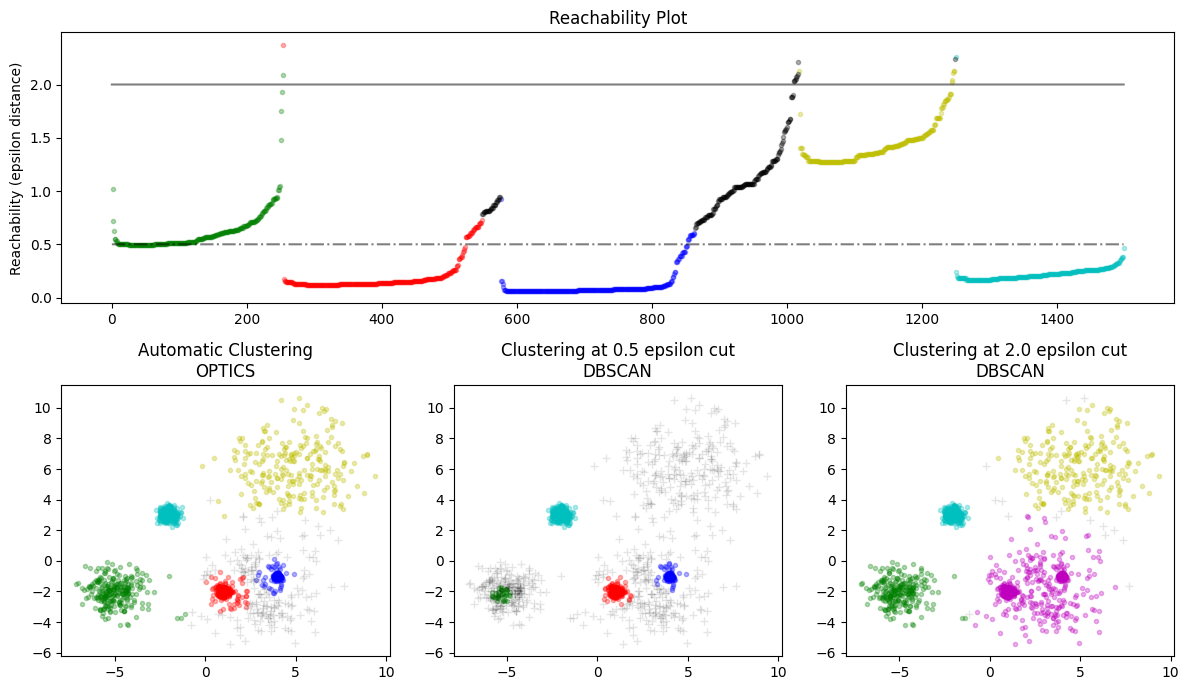

In [ ]:
# Authors: The scikit-learn developers
# SPDX-License-Identifier: BSD-3-Clause

import matplotlib.gridspec as gridspec

from sklearn.cluster import OPTICS, cluster_optics_dbscan

# Generate sample data

np.random.seed(0)
n_points_per_cluster = 250

C1 = [-5, -2] + 0.8 * np.random.randn(n_points_per_cluster, 2)
C2 = [4, -1] + 0.1 * np.random.randn(n_points_per_cluster, 2)
C3 = [1, -2] + 0.2 * np.random.randn(n_points_per_cluster, 2)
C4 = [-2, 3] + 0.3 * np.random.randn(n_points_per_cluster, 2)
C5 = [3, -2] + 1.6 * np.random.randn(n_points_per_cluster, 2)
C6 = [5, 6] + 2 * np.random.randn(n_points_per_cluster, 2)
X = np.vstack((C1, C2, C3, C4, C5, C6))

clust = OPTICS(min_samples=50, xi=0.05, min_cluster_size=0.05)

# Run the fit
clust.fit(X)

labels_050 = cluster_optics_dbscan(
    reachability=clust.reachability_,
    core_distances=clust.core_distances_,
    ordering=clust.ordering_,
    eps=0.5,
)
labels_200 = cluster_optics_dbscan(
    reachability=clust.reachability_,
    core_distances=clust.core_distances_,
    ordering=clust.ordering_,
    eps=2,
)

space = np.arange(len(X))
reachability = clust.reachability_[clust.ordering_]
labels = clust.labels_[clust.ordering_]

plt.figure(figsize=(12, 7))
G = gridspec.GridSpec(2, 3)
ax1 = plt.subplot(G[0, :])
ax2 = plt.subplot(G[1, 0])
ax3 = plt.subplot(G[1, 1])
ax4 = plt.subplot(G[1, 2])

# Reachability plot
colors = ["g.", "r.", "b.", "y.", "c."]
for klass, color in enumerate(colors):
    Xk = space[labels == klass]
    Rk = reachability[labels == klass]
    ax1.plot(Xk, Rk, color, alpha=0.3)
ax1.plot(space[labels == -1], reachability[labels == -1], "k.", alpha=0.3)
ax1.plot(space, np.full_like(space, 2.0, dtype=float), "k-", alpha=0.5)
ax1.plot(space, np.full_like(space, 0.5, dtype=float), "k-.", alpha=0.5)
ax1.set_ylabel("Reachability (epsilon distance)")
ax1.set_title("Reachability Plot")

# OPTICS
colors = ["g.", "r.", "b.", "y.", "c."]
for klass, color in enumerate(colors):
    Xk = X[clust.labels_ == klass]
    ax2.plot(Xk[:, 0], Xk[:, 1], color, alpha=0.3)
ax2.plot(X[clust.labels_ == -1, 0], X[clust.labels_ == -1, 1], "k+", alpha=0.1)
ax2.set_title("Automatic Clustering\nOPTICS")

# DBSCAN at 0.5
colors = ["g.", "r.", "b.", "c."]
for klass, color in enumerate(colors):
    Xk = X[labels_050 == klass]
    ax3.plot(Xk[:, 0], Xk[:, 1], color, alpha=0.3)
ax3.plot(X[labels_050 == -1, 0], X[labels_050 == -1, 1], "k+", alpha=0.1)
ax3.set_title("Clustering at 0.5 epsilon cut\nDBSCAN")

# DBSCAN at 2.
colors = ["g.", "m.", "y.", "c."]
for klass, color in enumerate(colors):
    Xk = X[labels_200 == klass]
    ax4.plot(Xk[:, 0], Xk[:, 1], color, alpha=0.3)
ax4.plot(X[labels_200 == -1, 0], X[labels_200 == -1, 1], "k+", alpha=0.1)
ax4.set_title("Clustering at 2.0 epsilon cut\nDBSCAN")

plt.tight_layout()
plt.show()

### HDBSCAN

Ещё один метод, развивающий DBSCAN, направленный на более стабильную работу при варьировании гиперпараметров.



1. [How HDBSCAN Works](https://hdbscan.readthedocs.io/en/latest/how_hdbscan_works.html)
2. [HDBSCAN demo](https://scikit-learn.org/stable/auto_examples/cluster/plot_hdbscan.html#sphx-glr-auto-examples-cluster-plot-hdbscan-py)

### Итог

<details>
<summary><b>Достоинства</b></summary>

1. OPTICS позволяет обнаруживать кластеры с переменной плотностью.
2. HDBSCAN позволяет автоматически определять оптимальное число кластеров за счёт построения иерархической структуры. Он минимизирует влияние параметров, заменяя жесткий выбор $\epsilon$ на более интуитивные параметры (например, минимальный размер кластера).

</details>

<details>
<summary><b>Недостатки</b></summary>

1. OPTICS для выделения кластеров требует дополнительной интерпретации reachability-диаграммы, что может осложнить автоматизацию процесса. Метод чувствительнее к настройке гиперпараметров.
2. HDBSCAN наследует проблемы Иерархической кластеризации - вычислительная сложность и визуальная интерпретация.

</details>

## KNN и К-средних на MNIST

Общие 10 000 обучающих и 2 000 тестовых изображений из стандартного разбиения MNIST. Для K-средних номер кластера сопоставляется с наиболее частой цифрой только по обучающей части.


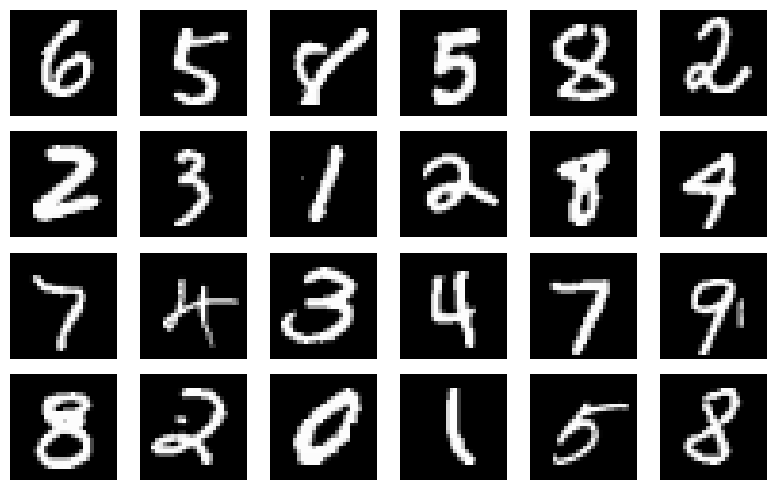

In [ ]:
from torchvision import datasets as tdatasets
from sklearn.model_selection import train_test_split

def get_mnist_data(root="./data", train_size=10000, test_size=2000):
    train = tdatasets.MNIST(root=root, train=True, download=True)
    test = tdatasets.MNIST(root=root, train=False, download=True)
    train_indices, _ = train_test_split(
        np.arange(len(train)), train_size=train_size,
        stratify=train.targets.numpy(), random_state=42,
    )
    test_indices, _ = train_test_split(
        np.arange(len(test)), train_size=test_size,
        stratify=test.targets.numpy(), random_state=42,
    )
    X_train = train.data[train_indices].reshape(-1, 784).numpy().astype(np.float32) / 255
    X_test = test.data[test_indices].reshape(-1, 784).numpy().astype(np.float32) / 255
    y_train = train.targets[train_indices].numpy()
    y_test = test.targets[test_indices].numpy()

    fig, axes = plt.subplots(4, 6, figsize=(8, 5))
    for image, ax in zip(X_train[:24], axes.flat):
        ax.imshow(image.reshape(28, 28), cmap="gray")
        ax.axis("off")
    plt.tight_layout()
    plt.show()
    return X_train, y_train, X_test, y_test

X_mnist, y_mnist, X_mnist_test, y_mnist_test = get_mnist_data()


In [ ]:
from sklearn.cluster import KMeans
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report


In [ ]:
n_clusters = 10
kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
kmeans.fit(X_mnist)

def map_clusters_to_labels(y_true, y_pred, n_clusters):
    mapping = {}
    for cluster in range(n_clusters):
        labels, counts = np.unique(y_true[y_pred == cluster], return_counts=True)
        mapping[cluster] = labels[np.argmax(counts)]
    return mapping

cluster_to_label = map_clusters_to_labels(y_mnist, kmeans.labels_, n_clusters)
kmeans_test_clusters = kmeans.predict(X_mnist_test)
y_pred_labels = np.array([cluster_to_label[cluster] for cluster in kmeans_test_clusters])
print(classification_report(y_mnist_test, y_pred_labels, digits=3, zero_division=0))


              precision    recall  f1-score   support

           0      0.942     0.750     0.835       196
           1      0.608     0.991     0.754       227
           2      0.897     0.631     0.741       206
           3      0.476     0.693     0.565       202
           4      0.394     0.332     0.360       196
           5      0.000     0.000     0.000       178
           6      0.851     0.802     0.826       192
           7      0.483     0.413     0.445       206
           8      0.480     0.564     0.519       195
           9      0.345     0.485     0.403       202

    accuracy                          0.577      2000
   macro avg      0.548     0.566     0.545      2000
weighted avg      0.554     0.577     0.552      2000



In [ ]:
knn_mnist = KNeighborsClassifier(
    n_neighbors=50, weights="uniform", metric="euclidean", algorithm="brute",
)
knn_mnist.fit(X_mnist, y_mnist)
y_pred_knn = knn_mnist.predict(X_mnist_test)
print(classification_report(y_mnist_test, y_pred_knn, digits=3, zero_division=0))


              precision    recall  f1-score   support

           0      0.950     0.969     0.960       196
           1      0.787     0.991     0.877       227
           2      0.982     0.796     0.879       206
           3      0.926     0.936     0.931       202
           4      0.951     0.883     0.915       196
           5      0.916     0.860     0.887       178
           6      0.944     0.958     0.951       192
           7      0.906     0.893     0.900       206
           8      0.977     0.877     0.924       195
           9      0.855     0.936     0.894       202

    accuracy                          0.911      2000
   macro avg      0.919     0.910     0.912      2000
weighted avg      0.917     0.911     0.911      2000



## Метрики качества кластеризации

Подробный обзор на [вики](https://neerc.ifmo.ru/wiki/index.php?title=%D0%9E%D1%86%D0%B5%D0%BD%D0%BA%D0%B0_%D0%BA%D0%B0%D1%87%D0%B5%D1%81%D1%82%D0%B2%D0%B0_%D0%B2_%D0%B7%D0%B0%D0%B4%D0%B0%D1%87%D0%B5_%D0%BA%D0%BB%D0%B0%D1%81%D1%82%D0%B5%D1%80%D0%B8%D0%B7%D0%B0%D1%86%D0%B8%D0%B8).

### Теорема невозможности Клейнберга

[**Теорема невозможности Клейнберга:**](https://www.cs.cornell.edu/home/kleinber/nips15.pdf) Для множества объектов, состоящего из двух и более элементов, не существует алгоритма кластеризации, который был бы одновременно масштабно-инвариантным, согласованным и полным.

Для фиксированного множества объектов $X$ обозначим через $a$ алгоритм кластеризации, а через $a(\rho)$ — полученное разбиение при функции расстояния $\rho$.

Давайте выделим следующие свойства алгоритмов кластеризации в качестве аксиом:

1. Алгоритм $a$ является **масштабно инвариантным**, если для любой функции расстояния $\rho$ и любой константы $\alpha > 0$ выполняется $a(\rho)=a(\alpha\rho)$.
2. Определим множество всех возможных [разбиений](https://ru.wikipedia.org/wiki/%D0%A0%D0%B0%D0%B7%D0%B1%D0%B8%D0%B5%D0%BD%D0%B8%D0%B5_%D0%BC%D0%BD%D0%BE%D0%B6%D0%B5%D1%81%D1%82%D0%B2%D0%B0) множества $X$: $\{U_c\}_{c\in C}$.

Например,
$$X = \{1, 2, 3\}\quad\Rightarrow\quad
\{U_c\}_{c\in C}=\bigl\{
\{\{1,2,3\}\},
\{\{1\},\{2,3\}\},
\{\{2\},\{1,3\}\},
\{\{3\},\{1,2\}\},
\{\{1\},\{2\},\{3\}\}
\bigr\}.$$

Алгоритм $a$ называется **полным**, если для любого $U_c$ существует функция расстояния $\rho$, при которой $a(\rho)=U_c$.
3. Алгоритм $a$ называется **согласованным**, если результат кластеризации не изменяется после допустимого преобразования функции расстояния: $a(\rho')=a(\rho)$.

Функция расстояния $\rho'$ является **допустимым преобразованием** функции расстояния $\rho$, если относительно кластеров разбиения $a(\rho)$:
1. $\rho'(x_i,x_j)\leqslant\rho(x_i,x_j)$, если $x_i,x_j$ лежат в одном и том же кластере.
2. $\rho'(x_i,x_j)\geqslant\rho(x_i,x_j)$, если $x_i,x_j$ лежат в разных кластерах.

Клейнберг также [показал](https://www.cs.cornell.edu/home/kleinber/nips15.pdf), что иерархический метод кластеризации по методу одиночной связи $R_{\min}(U,V)=\min_{u\in U,\,v\in V}\rho(u,v)$ при соответствующем выборе правила остановки удовлетворяет любым двум из трёх аксиом; для разных пар аксиом используются разные правила остановки.


### Оценка качества кластеризации

Проблема *оценки качества* в задаче кластеризации **трудноразрешима**, как минимум, по двум причинам:
* Теорема невозможности Клейнберга — алгоритмы кластеризации имеют разные полезные свойства.
* Априорная информация о количестве кластеров не всегда доступна. Многие алгоритмы кластеризации не способны определить настоящее количество кластеров в данных. Чаще всего количество кластеров подается на вход алгоритма и подбирается несколькими запусками алгоритма.

Запишем реальные классы $X = \{X_1, X_2, \dots, X_r\}$ и выделенные кластеры $Y = \{Y_1, Y_2, \dots, Y_s\}$. Определим *таблицу сопряжённости*

$$
\begin{array}{c|cccc|c}
    X \setminus Y & Y_1 & Y_2 & \cdots & Y_s & \text{sums} \\
    \hline
    X_1 & n_{11} & n_{12} & \cdots & n_{1s} & a_1 \\
    X_2 & n_{21} & n_{22} & \cdots & n_{2s} & a_2 \\
    \vdots & \vdots & \vdots & \ddots & \vdots & \vdots \\
    X_r & n_{r1} & n_{r2} & \cdots & n_{rs} & a_r \\
    \hline
    \text{sums} & b_1 & b_2 & \cdots & b_s &
\end{array}
$$

$$
n_{ij}=|X_i\cap Y_j|,\qquad
a_i=\sum_{j=1}^{s}n_{ij},\qquad
b_j=\sum_{i=1}^{r}n_{ij},\qquad
n=\sum_{i=1}^{r}\sum_{j=1}^{s}n_{ij}.
$$

$$
\begin{aligned}
TP &= \sum_{i=1}^{r}\sum_{j=1}^{s}\binom{n_{ij}}{2},\\
FP &= \sum_{j=1}^{s}\binom{b_j}{2}-TP,\\
FN &= \sum_{i=1}^{r}\binom{a_i}{2}-TP,\\
TN &= \binom{n}{2}-TP-FP-FN.
\end{aligned}
$$

*Индекс Rand*:

$$RI=\frac{TP+TN}{TP+FP+FN+TN}\in[0,1].$$

*Скорректированный индекс Rand*:

$$
ARI = \frac{
\displaystyle\sum_{i=1}^{r}\sum_{j=1}^{s}\binom{n_{ij}}{2}
- \dfrac{\displaystyle\left(\sum_{i=1}^{r}\binom{a_i}{2}\right)\left(\sum_{j=1}^{s}\binom{b_j}{2}\right)}{\displaystyle\binom{n}{2}}
}{
\displaystyle\frac{1}{2}\left(\sum_{i=1}^{r}\binom{a_i}{2}+\sum_{j=1}^{s}\binom{b_j}{2}\right)
- \dfrac{\displaystyle\left(\sum_{i=1}^{r}\binom{a_i}{2}\right)\left(\sum_{j=1}^{s}\binom{b_j}{2}\right)}{\displaystyle\binom{n}{2}}
}.
$$

$$ARI=\frac{RI-\mathbb E_{\pi}[RI]}{1-\mathbb E_{\pi}[RI]}.$$

Здесь $\pi$ — равномерная случайная перестановка меток кластеров между объектами при фиксированных истинных классах и размерах кластеров.

$\mathbb E_{\pi}[RI]$ — средний RI, который получился бы, если бы алгоритм случайно распределял объекты по кластерам, сохраняя размеры найденных кластеров.


In [ ]:
from sklearn.metrics import rand_score, adjusted_rand_score

X, y = create_clusters()
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X)

In [ ]:
%%time
ri_score = rand_score(y, kmeans.labels_)
ari_score = adjusted_rand_score(y, kmeans.labels_)
print(f"Rand Index (RI): {ri_score:.4f}")
print(f"Adjusted Rand Index (ARI): {ari_score:.4f}")

Rand Index (RI): 0.8818
Adjusted Rand Index (ARI): 0.3652
CPU times: user 19.3 ms, sys: 0 ns, total: 19.3 ms
Wall time: 18.5 ms


#### **Что делать в случае, если данные являются неразмеченными?**

Метрики, отражающие качество кластеризации без учёта априорной информации о разметке, называются *внутренними* (анализируют внутреннюю структуру кластеров)

* *Компактность/Отделимость* кластеров оценивают расстояние объектов внутри/вне кластеров. Чем ближе/дальше объекты, тем лучше разделение:
$$
WSS = \sum_{i=1}^s\sum_{j=1}^{|Y_i|}\|x_{ij} - \bar{x}_i\|^2 \rightarrow \min, \quad BSS = \sum_{i=1}^s |Y_i|\cdot\|\bar{x}_i - \bar{x}\|^2 \rightarrow \max
$$
* *Индекс Данна* показывает отношение отделимости кластеров к их компактности:
$$
\delta = \dfrac{\min\limits_{i \neq j}\ \min\limits_{u\in Y_i,\, v\in Y_j}\rho(u,v)}{\max\limits_{k}\ \max\limits_{u,v\in Y_k}\rho(u,v)} \rightarrow \max
$$
* *Силуэт* показывает, насколько объект похож на свой кластер по сравнению с другими кластерами.
$$
Sil = \dfrac{1}{n}\sum_{i=1}^s\sum_{x_j \in Y_i}\dfrac{bss(x_j, Y_i) - wss(x_j, Y_i)}{\max\{bss(x_j, Y_i), wss(x_j, Y_i)\}} \in [-1, 1] \rightarrow \max
$$
* $Sil = 1$ - идеальное разделение
* $Sil = -1$ - отсутствие разделения: точки кластера могут быть ближе к другому кластеру, чем к центру.

$$
bss(x_j, Y_i) = \min_{Y_k \in Y \backslash Y_i}\left\{\dfrac{1}{|Y_k|}\sum_{x_i \in Y_k}\|x_j - x_i\|\right\},
$$
Cреднее расстояние от $x_j \in Y_i$ до ближайшего кластера $Y_k$ (отделимость)
$$
wss(x_j, Y_i) = \dfrac{1}{|Y_i| - 1}\sum_{x_i \in Y_i,\, x_i \neq x_j}\|x_j - x_i\|,
$$
Cреднее расстояние внутри $Y_i$ относительно $x_j$ (компактность)

* *Индекс Девиса-Болдуина* оценивает, насколько кластеры отличаются друг от друга с учётом их компактности
$$
\bar{x}_i = \frac{1}{|Y_i|}\sum_{x\in Y_i}x,\qquad
\sigma_i = \frac{1}{|Y_i|}\sum_{x\in Y_i}\|x-\bar{x}_i\|_2.
$$
$$
DB = \frac{1}{s}\sum_{i=1}^{s}\max_{j\neq i}
\frac{\sigma_i+\sigma_j}{\|\bar{x}_i-\bar{x}_j\|_2}
\geqslant 0\rightarrow\min.
$$

In [ ]:
from sklearn.metrics import silhouette_score, davies_bouldin_score

In [ ]:
%%time
silhouette_avg = silhouette_score(X, kmeans.labels_)
db_avg = davies_bouldin_score(X, kmeans.labels_)

print(f"Silhouette Score: {silhouette_avg:.4f}")
print(f"Davies Bouldin Score: {db_avg:.4f}")

Silhouette Score: 0.0587
Davies Bouldin Score: 2.7760
CPU times: user 7min 33s, sys: 15.6 s, total: 7min 48s
Wall time: 4min 57s


#### **Какая сложность описанных метрик?**

* Силуэт - $\mathcal{O}(n^2d)$, где $n$ - число примеров, $d$ - размерность $x$
* Индекс Девиса-Болдуина - $\mathcal{O}(nd + s^2d) \overset{s \ll n}{\approx} \mathcal{O}(nd)$, где $s$ - количество кластеров

In [ ]:
%%time
db_avg = davies_bouldin_score(X, kmeans.labels_)
print(f"Davies Bouldin Score: {db_avg:.4f}")

Davies Bouldin Score: 3.9399
CPU times: user 1.34 s, sys: 707 µs, total: 1.34 s
Wall time: 1.87 s


## Ссылки

- Визуализация работы [K-means](https://www.naftaliharris.com/blog/visualizing-k-means-clustering/)
- Визуализация [DBSCAN](https://www.naftaliharris.com/blog/visualizing-dbscan-clustering/).
- [Иерархическая кластеризация](https://neerc.ifmo.ru/wiki/index.php?title=%D0%98%D0%B5%D1%80%D0%B0%D1%80%D1%85%D0%B8%D1%87%D0%B5%D1%81%D0%BA%D0%B0%D1%8F_%D0%BA%D0%BB%D0%B0%D1%81%D1%82%D0%B5%D1%80%D0%B8%D0%B7%D0%B0%D1%86%D0%B8%D1%8F)
- [DBSCAN vs OPTICS](https://www.atlantbh.com/clustering-algorithms-dbscan-vs-optics/)
    - [OPTICS demo](https://scikit-learn.org/stable/auto_examples/cluster/plot_optics.html#sphx-glr-auto-examples-cluster-plot-optics-py)
- HDBSCAN
    - [How HDBSCAN Works](https://hdbscan.readthedocs.io/en/latest/how_hdbscan_works.html)
    - [HDBSCAN demo](https://scikit-learn.org/stable/auto_examples/cluster/plot_hdbscan.html#sphx-glr-auto-examples-cluster-plot-hdbscan-py)
- [Метрики качества](https://neerc.ifmo.ru/wiki/index.php?title=%D0%9E%D1%86%D0%B5%D0%BD%D0%BA%D0%B0_%D0%BA%D0%B0%D1%87%D0%B5%D1%81%D1%82%D0%B2%D0%B0_%D0%B2_%D0%B7%D0%B0%D0%B4%D0%B0%D1%87%D0%B5_%D0%BA%D0%BB%D0%B0%D1%81%D1%82%D0%B5%D1%80%D0%B8%D0%B7%D0%B0%D1%86%D0%B8%D0%B8)